<div style="background:linear-gradient(135deg,#1a3a5c 0%,#2d6a9f 100%);padding:28px;border-radius:10px;color:white">

# Projet 12 — Détection automatique de faux billets
## Notebook d'analyse · Préparation, exploration, modélisation et application

**Client** : *ONCFM* — Organisation nationale de lutte contre le faux-monnayage
**Commanditaire** : Marie, responsable de la lutte contre le faux-monnayage
**Mission** : prédire si un billet est vrai ou faux à partir de ses seules dimensions géométriques

</div>

---

### Objectif de ce notebook

1. Construire, à partir du fichier fourni, **un jeu de données propre** (« un billet = une ligne », zéro valeur manquante) et en faire l'**analyse descriptive** demandée.
2. Mettre en concurrence les **4 méthodes** demandées (régression logistique, k-means, KNN, random forest) et choisir la plus performante.
3. Sauvegarder le modèle retenu pour l'**application** livrée dans un script séparé.

### Sources de données

| Source | Fichier | Séparateur | Contenu |
|---|---|---|---|
| ONCFM — fichier de paramétrage | `billets.csv` | `;` | 1 500 billets scannés : 6 mesures (mm) + nature du billet (`is_genuine`) |
| ONCFM — format de production | `billets_production.csv` | `,` | billets à classer : 6 mesures + identifiant `id`, sans la nature du billet |

### Contraintes du cahier des charges

| Exigence | Cible |
|---|---|
| Variables utilisées par l'algorithme | les 6 dimensions géométriques uniquement |
| Fichier de paramétrage | 1 500 billets : 1 000 vrais, 500 faux |
| Analyse descriptive | répartition des dimensions, nombre de vrais / faux |
| Méthodes à comparer | régression logistique, k-means (prédiction par les centroïdes), KNN, random forest |
| Évaluation | faux positifs et faux négatifs via une matrice de confusion |
| Priorité métier | identifier un **maximum de faux billets** |
| Livrable applicatif | un script : entrée = valeurs d'un billet **ou** chemin vers un CSV ; sortie **binaire** |

> **Convention utilisée dans tout le notebook** : la classe **positive (1) = FAUX billet**, car c'est ce que l'on cherche à détecter.
> - **Faux négatif (FN)** = faux billet prédit « vrai » → *erreur la plus grave* (le faux repart en circulation).
> - **Faux positif (FP)** = vrai billet prédit « faux » → coûte une vérification manuelle.

### Sommaire

| § | Étape |
|---|---|
| | **Partie A — Préparation et nettoyage** |
| 1 | Configuration de l'environnement |
| 2 | Chargement des données brutes |
| 3 | Exploration de la structure |
| 4 | Contrôle qualité des sources (doublons, valeurs manquantes, cohérence) |
| 5 | Traitement des valeurs manquantes (régression linéaire) |
| 6 | Contrôle des doublons et conformité au cahier des charges |
| | **Partie B — Analyse exploratoire** |
| 7 | Analyse univariée |
| 8 | Analyse des valeurs extrêmes (outliers) |
| 9 | Analyse bivariée |
| 10 | Analyse en composantes principales (ACP) |
| 11 | Export du jeu de données nettoyé |
| | **Partie C — Modélisation et application** |
| 12 | Prétraitement (X / y, train / test, standardisation) |
| 13 | Modélisation : régression logistique, KNN, random forest, k-means |
| 14 | Sélection du meilleur modèle |
| 15 | Sauvegarde du modèle et test sur `billets_production.csv` |
| 16 | Synthèse |

---
## 1. Configuration de l'environnement

On importe les bibliothèques, on règle l'affichage et on définit les chemins **une seule fois**.
Les chemins sont **relatifs** : les fichiers `billets.csv` et `billets_production.csv` doivent être **dans le même dossier que ce notebook**. Le notebook fonctionnera ainsi sur n'importe quel poste, sans modification.

In [1]:
# =============================================================================
# 1. CONFIGURATION
# =============================================================================

import os
import warnings

# Windows + Anaconda (MKL) : K-means affiche sinon un avertissement de « fuite mémoire ».
# Limiter le nombre de threads le supprime ; cette ligne doit être exécutée AVANT l'import de numpy et scikit-learn.
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

import sklearn
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_validate, cross_val_predict)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.experimental import enable_iterative_imputer  # noqa: F401 (active IterativeImputer)
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             RocCurveDisplay, silhouette_score, silhouette_samples, mean_squared_error)
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")   # sécurité si le noyau n'a pas été redémarré

# --- Affichage des tableaux ---
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.precision", 3)

# --- Style des graphiques ---
sns.set_theme(style="whitegrid")
COULEURS = {"Vrai": "#2E6FBA", "Faux": "#D1495B"}   # bleu = vrai, rouge = faux, dans tout le notebook
plt.rcParams["axes.titleweight"] = "bold"

# --- Constantes du projet ---
RANDOM_STATE = 42          # graine aléatoire : résultats reproductibles à l'identique
VARIABLES = ["diagonal", "height_left", "height_right", "margin_low", "margin_up", "length"]   # ordre du cahier des charges

# --- Chemins (relatifs : fichiers à côté du notebook) ---
FICHIER_BRUT = "billets.csv"
FICHIER_PRODUCTION = "billets_production.csv"
FICHIER_NETTOYE = "billets_nettoyes.csv"
FICHIER_DICTIONNAIRE = "dictionnaire_variables.csv"

# --- Petit utilitaire de mise en page des sorties texte ---
def titre(txt, char="=", larg=78):
    # Affiche un titre encadré dans la sortie de la cellule.
    print(char * larg)
    print(txt)
    print(char * larg)

titre("CONFIGURATION TERMINÉE")
print(f"pandas {pd.__version__}  |  numpy {np.__version__}  |  scikit-learn {sklearn.__version__}  |  seaborn {sns.__version__}")
print(f"Dossier de travail : {os.getcwd()}")
for f in [FICHIER_BRUT, FICHIER_PRODUCTION]:
    print(f"   {f:25s} : {'présent ✅' if os.path.exists(f) else 'INTROUVABLE ❌ (le placer à côté du notebook)'}")

CONFIGURATION TERMINÉE
pandas 2.3.3  |  numpy 2.3.5  |  scikit-learn 1.7.2  |  seaborn 0.13.2
Dossier de travail : C:\Users\sabah\Desktop\Projet_Openclassrooms\Projet_12
   billets.csv               : présent ✅
   billets_production.csv    : présent ✅


---
## 2. Chargement des données brutes

Le fichier est chargé tel quel, sans aucune transformation.
**Principe de base : on ne modifie jamais les données brutes.** Toute transformation se fait dans une copie (`df`), de sorte qu'on puisse toujours revenir au point de départ (`billets_brut`).

Attention: `billets.csv` utilise le **point-virgule** comme séparateur : on le précise avec `sep=";"`.

In [2]:
# =============================================================================
# 2. CHARGEMENT DES DONNÉES BRUTES
# =============================================================================

billets_brut = pd.read_csv(FICHIER_BRUT, sep=";")
df = billets_brut.copy()                       # copie de travail

titre("VOLUMÉTRIE")
print(f"{FICHIER_BRUT} : {df.shape[0]:,} lignes x {df.shape[1]} colonnes "
      f"({df.memory_usage(deep=True).sum() / 1024:.0f} Ko)")

VOLUMÉTRIE
billets.csv : 1,500 lignes x 7 colonnes (72 Ko)


---
## 3. Exploration de la structure

Avant tout nettoyage, on regarde **comment les données sont organisées**. C'est ce diagnostic qui déterminera les traitements à appliquer.

In [3]:
# =============================================================================
# 3. EXPLORATION DE LA STRUCTURE
# =============================================================================

titre("APERÇU (5 premières lignes)")
display(df.head())

print()
titre("TYPES ET COMPLÉTUDE DES COLONNES", "-")
df.info()

APERÇU (5 premières lignes)


,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83
1,True,171.46,103.36,103.66,3.77,2.99,113.09
2,True,172.69,104.48,103.50,4.40,2.94,113.16
3,True,171.36,103.91,103.94,3.62,3.01,113.51
4,True,171.73,104.28,103.46,4.04,3.48,112.54



------------------------------------------------------------------------------
TYPES ET COMPLÉTUDE DES COLONNES
------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   is_genuine    1500 non-null   bool   
 1   diagonal      1500 non-null   float64
 2   height_left   1500 non-null   float64
 3   height_right  1500 non-null   float64
 4   margin_low    1463 non-null   float64
 5   margin_up     1500 non-null   float64
 6   length        1500 non-null   float64
dtypes: bool(1), float64(6)
memory usage: 71.9 KB


In [4]:
# --- Cardinalité de chaque colonne ---------------------------------------

resume = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "valeurs_uniques": df.nunique(),
    "valeurs_manquantes": df.isna().sum(),
    "exemple": [df[c].dropna().iloc[0] for c in df.columns],
})
resume["% manquant"] = (resume["valeurs_manquantes"] / len(df) * 100).round(2)

titre("CARDINALITÉ DES COLONNES")
display(resume)

CARDINALITÉ DES COLONNES


,type,valeurs_uniques,valeurs_manquantes,exemple,% manquant
is_genuine,bool,2,0,True,0.00
diagonal,float64,159,0,171.81,0.00
height_left,float64,155,0,104.86,0.00
height_right,float64,170,0,104.95,0.00
margin_low,float64,285,37,4.52,2.47
margin_up,float64,123,0,2.89,0.00
length,float64,336,0,112.83,0.00


In [5]:
# --- Les colonnes correspondent-elles au cahier des charges ? -----------------

titre("CONFORMITÉ DES COLONNES AU CAHIER DES CHARGES")
manquantes = [v for v in VARIABLES if v not in df.columns]
en_trop = [c for c in df.columns if c not in VARIABLES + ["is_genuine"]]
print(f"Variables géométriques attendues : {VARIABLES}")
print(f"   absentes du fichier : {manquantes if manquantes else 'aucune'}")
print(f"   colonnes inattendues : {en_trop if en_trop else 'aucune'}")
print(f"Cible 'is_genuine' : type {df['is_genuine'].dtype}, valeurs {sorted(df['is_genuine'].unique())}")
print()
print("→ Le fichier est déjà au FORMAT LARGE : une ligne = un billet, une colonne = une mesure.")
print("→ Aucun pivot ni aucune fusion n'est nécessaire (contrairement à des données au format long).")

CONFORMITÉ DES COLONNES AU CAHIER DES CHARGES
Variables géométriques attendues : ['diagonal', 'height_left', 'height_right', 'margin_low', 'margin_up', 'length']
   absentes du fichier : aucune
   colonnes inattendues : aucune
Cible 'is_genuine' : type bool, valeurs [np.False_, np.True_]

→ Le fichier est déjà au FORMAT LARGE : une ligne = un billet, une colonne = une mesure.
→ Aucun pivot ni aucune fusion n'est nécessaire (contrairement à des données au format long).


**Constats** : 1 500 lignes, 7 colonnes, aucune colonne inattendue : les **6 mesures** du cahier des charges (en mm, type `float`) et la cible **`is_genuine`** (booléen `True` = vrai billet). Une seule colonne est incomplète : **`margin_low`** (1 463 valeurs renseignées sur 1 500). Les données sont prêtes à l'emploi dans leur forme : le travail portera sur la **qualité**, pas sur la structure.

---
## 4. Contrôle qualité des sources

Trois contrôles systématiques avant toute transformation :

1. **Doublons** — lignes strictement identiques, puis billets aux 6 mesures identiques
2. **Valeurs manquantes** — combien, où, et sur quels types de billets
3. **Cohérence** — les mesures sont-elles physiquement plausibles et la répartition vrai / faux conforme ?

In [6]:
# =============================================================================
# 4. CONTRÔLE QUALITÉ
# =============================================================================

titre("4.1  DOUBLONS")
n_total = df.duplicated().sum()
n_mesures = df.duplicated(subset=VARIABLES).sum()
print(f"Lignes strictement identiques            : {n_total}")
print(f"Billets aux 6 mesures identiques         : {n_mesures}")
if n_total == 0 and n_mesures == 0:
    print("→ Aucun doublon. Aucune déduplication nécessaire.")

4.1  DOUBLONS
Lignes strictement identiques            : 0
Billets aux 6 mesures identiques         : 0
→ Aucun doublon. Aucune déduplication nécessaire.


In [7]:
titre("4.2  VALEURS MANQUANTES DANS LES DONNÉES BRUTES")

na = df.isna().sum()
tab_na = na.to_frame("nb_manquants").assign(pct=lambda t: (t.nb_manquants / len(df) * 100).round(2))
display(tab_na)

df["type"] = df["is_genuine"].map({True: "Vrai", False: "Faux"})   # libellé lisible pour tableaux et graphiques
manquants = df[df["margin_low"].isna()]
print("Répartition des billets sans margin_low :")
display(manquants["type"].value_counts().to_frame("nb"))

4.2  VALEURS MANQUANTES DANS LES DONNÉES BRUTES


,nb_manquants,pct
is_genuine,0,0.00
diagonal,0,0.00
height_left,0,0.00
height_right,0,0.00
margin_low,37,2.47
margin_up,0,0.00
length,0,0.00


Répartition des billets sans margin_low :


,nb
type,
Vrai,29
Faux,8


In [8]:
titre("4.3  COHÉRENCE DES MESURES ET DE LA CIBLE")

controles_coherence = pd.DataFrame({
    "min": df[VARIABLES].min(), "max": df[VARIABLES].max(),
    "valeurs <= 0": (df[VARIABLES] <= 0).sum(),
    "étendue (max - min)": df[VARIABLES].max() - df[VARIABLES].min(),
})
display(controles_coherence)

ecart_hauteurs = (df["height_left"] - df["height_right"]).abs()
print(f"Écart entre hauteur gauche et droite : médiane {ecart_hauteurs.median():.2f} mm, "
      f"max {ecart_hauteurs.max():.2f} mm")
print(f"Longueur toujours supérieure aux hauteurs : {(df['length'] > df[['height_left', 'height_right']].max(axis=1)).all()}")
print(f"Diagonale toujours supérieure à la longueur : {(df['diagonal'] > df['length']).all()}")

repartition = df["type"].value_counts()[["Vrai", "Faux"]]
print(f"\nRépartition : {repartition['Vrai']} vrais, {repartition['Faux']} faux")
assert repartition["Vrai"] == 1000 and repartition["Faux"] == 500, "Répartition différente du cahier des charges"
print(" Conforme au cahier des charges : 1 000 vrais et 500 faux billets")

4.3  COHÉRENCE DES MESURES ET DE LA CIBLE


,min,max,valeurs <= 0,étendue (max - min)
diagonal,171.04,173.01,0,1.97
height_left,103.14,104.88,0,1.74
height_right,102.82,104.95,0,2.13
margin_low,2.98,6.90,0,3.92
margin_up,2.27,3.91,0,1.64
length,109.49,114.44,0,4.95


Écart entre hauteur gauche et droite : médiane 0.25 mm, max 1.58 mm
Longueur toujours supérieure aux hauteurs : True
Diagonale toujours supérieure à la longueur : True

Répartition : 1000 vrais, 500 faux
 Conforme au cahier des charges : 1 000 vrais et 500 faux billets


**Constats et décisions** :
- **Doublons** : aucun.
- **Valeurs manquantes** : 37 billets (2,5 %) sans `margin_low`, répartis sur **les deux types** (29 vrais, 8 faux) : ce n'est pas une particularité d'une seule classe → on peut les imputer sans biaiser l'analyse (§5).
- **Cohérence** : aucune mesure nulle ou négative ; les étendues restent de l'ordre de quelques millimètres ; la géométrie est respectée (diagonale > longueur > hauteurs) ; les deux hauteurs d'un même billet diffèrent de 0,25 mm en médiane (1,6 mm au maximum). **Aucune erreur de saisie détectée** → on conserve tous les billets.
- **Classes déséquilibrées 2/3 – 1/3** : un modèle naïf qui dirait toujours « vrai » aurait déjà 66,7 % d'exactitude. On ne jugera donc **pas** les modèles sur l'accuracy seule, et on utilisera un découpage **stratifié**.

---
## 5. Traitement des valeurs manquantes

Objectif : **zéro valeur manquante** dans le jeu de données analysé. Trois stratégies possibles, à justifier :

| Stratégie | Avantage | Inconvénient |
|---|---|---|
| Supprimer les 37 lignes | Simple | Perte de données ; et **en production**, un billet avec une mesure manquante ne pourrait pas être analysé |
| Remplacer par la moyenne / médiane | Simple | Ignore les liens entre variables ; `margin_low` est **bimodale** (vrais ≈ 4,1 / faux ≈ 5,2) : la moyenne (≈ 4,5) ne correspond à aucun des deux groupes |
| **Prédire la valeur par régression linéaire** à partir des 5 autres mesures | Utilise l'information disponible | Nécessite de vérifier la qualité du modèle |

**Décision : régression linéaire** (méthode attendue dans le projet), après avoir vérifié qu'elle est pertinente.

> **Choix important** : on n'utilise **pas** `is_genuine` comme variable explicative, même si cela améliorerait la prédiction. En production, la nature du billet est **justement ce que l'on cherche** : on ne peut pas s'en servir pour compléter une mesure manquante. On utilise donc uniquement les mesures géométriques, pour que la **même méthode** fonctionne à l'entraînement et en production.

### 5.1 Régression linéaire multiple : `margin_low` expliquée par les 5 autres mesures
On utilise **statsmodels**, qui affiche un tableau statistique complet (coefficients, p-values, R²), sur les 1 463 billets complets.

In [9]:
# =============================================================================
# 5. TRAITEMENT DES VALEURS MANQUANTES
# =============================================================================

df_reg = df.dropna(subset=["margin_low"])          # les 1 463 billets complets
modele_reg = smf.ols("margin_low ~ diagonal + height_left + height_right + margin_up + length", data=df_reg).fit()
print(modele_reg.summary())

                            OLS Regression Results                            
Dep. Variable:             margin_low   R-squared:                       0.477
Model:                            OLS   Adj. R-squared:                  0.476
Method:                 Least Squares   F-statistic:                     266.1
Date:                Sun, 18 Oct 2026   Prob (F-statistic):          2.60e-202
Time:                        10:03:53   Log-Likelihood:                -1001.3
No. Observations:                1463   AIC:                             2015.
Df Residuals:                    1457   BIC:                             2046.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       22.9948      9.656      2.382   

**Lecture du tableau** :
- **Prob (F-statistic)** ≈ 0 → le modèle dans son ensemble est **significatif**.
- **Toutes les variables** ont une p-value (colonne `P>|t|`) < 0,05 → chacune apporte une information significative ; on les garde toutes.
- `length` est de loin la plus influente (|t| ≈ 22,6) : +1 mm de longueur ⇒ −0,41 mm de `margin_low` en moyenne.
- **R² ≈ 0,48** : le modèle explique environ la moitié de la variance de `margin_low`. C'est modéré, mais bien meilleur qu'une simple moyenne (voir 5.3).
- La note *« condition number is large »* en bas du tableau n'indique **pas** ici une vraie colinéarité : elle vient du fait que les variables ne sont pas centrées (une diagonale vaut environ 172 mm alors que les écarts entre billets sont de quelques dixièmes de mm). Le vrai diagnostic de colinéarité est le **VIF**, calculé juste après.

### 5.2 Vérification des hypothèses de la régression linéaire
1. **Absence de colinéarité** entre variables explicatives → facteur d'inflation de la variance (**VIF**). Règle usuelle : VIF < 5 (ou < 10) = acceptable.
2. **Homoscédasticité** (variance des résidus constante) → test de **Breusch-Pagan**.
3. **Normalité des résidus** → test de **Shapiro-Wilk** + QQ-plot.

,variable,VIF
0,diagonal,1.01
1,height_left,1.14
2,height_right,1.23
3,margin_up,1.40
4,length,1.58


Breusch-Pagan  : p-value = 7.76e-16  -> variance non constante (hétéroscédasticité)
Shapiro-Wilk   : p-value = 8.54e-11  -> résidus non normaux


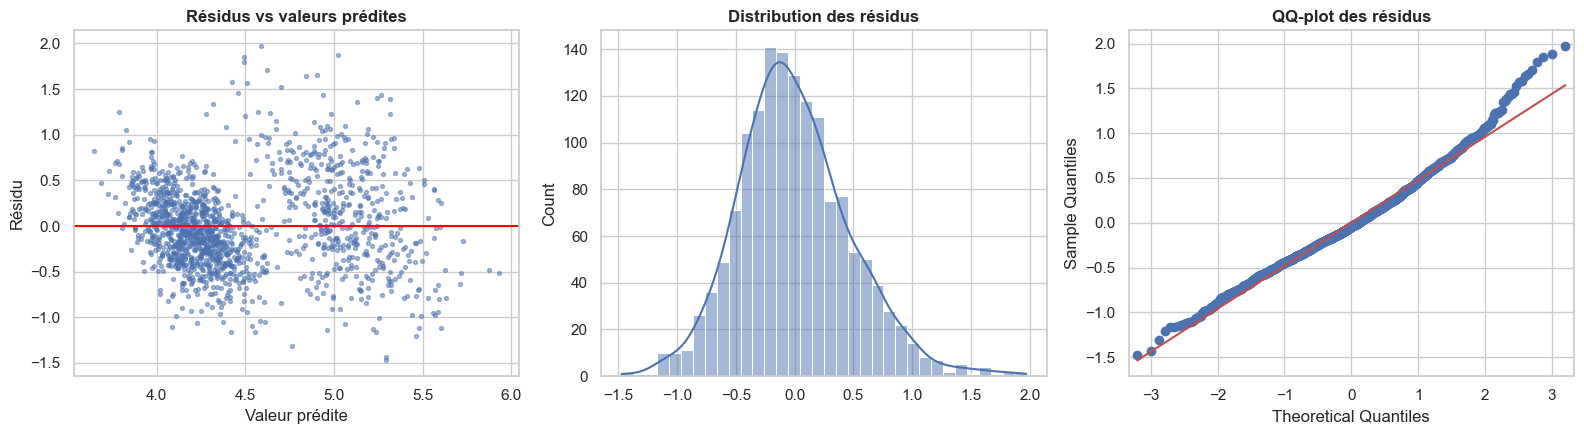

In [10]:
X_vif = sm.add_constant(df_reg[["diagonal", "height_left", "height_right", "margin_up", "length"]])
vif = pd.DataFrame({"variable": X_vif.columns[1:],
                    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])]})
display(vif.round(2))

p_bp = het_breuschpagan(modele_reg.resid, modele_reg.model.exog)[1]
p_sw = stats.shapiro(modele_reg.resid).pvalue
print(f"Breusch-Pagan  : p-value = {p_bp:.2e}  -> {'variance non constante (hétéroscédasticité)' if p_bp < 0.05 else 'homoscédasticité'}")
print(f"Shapiro-Wilk   : p-value = {p_sw:.2e}  -> {'résidus non normaux' if p_sw < 0.05 else 'résidus normaux'}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(modele_reg.fittedvalues, modele_reg.resid, s=8, alpha=0.5)
axes[0].axhline(0, color="red"); axes[0].set(title="Résidus vs valeurs prédites", xlabel="Valeur prédite", ylabel="Résidu")
sns.histplot(modele_reg.resid, kde=True, ax=axes[1]); axes[1].set(title="Distribution des résidus")
sm.qqplot(modele_reg.resid, line="s", ax=axes[2]); axes[2].set_title("QQ-plot des résidus")
plt.tight_layout(); plt.show()

**Interprétation (honnête) des hypothèses** :
-  **Colinéarité** : tous les VIF sont proches de 1 (max ≈ 1,6) → aucune colinéarité problématique.
-  **Homoscédasticité** et **normalité** des résidus sont **rejetées** par les tests. L'explication : `margin_low` est **bimodale** (un groupe « vrais » et un groupe « faux ») et une seule droite ne capte pas parfaitement ces deux populations.

**Est-ce bloquant pour imputer ?** Non. Ces deux hypothèses servent à rendre **fiables les tests et les intervalles de confiance**. Pour un usage de **prédiction ponctuelle** (remplir une valeur), l'estimation des moindres carrés reste **sans biais** dès lors que le modèle est correctement spécifié et sans colinéarité. Et l'enjeu est limité : 37 valeurs sur 1 500 (2,5 %). On vérifie surtout que l'imputation par régression **prédit mieux** qu'une simple moyenne.

### 5.3 La régression prédit-elle mieux que la moyenne ? (validation croisée)
On mesure l'erreur de prédiction (RMSE, en mm) sur des billets **dont on connaît la vraie valeur**, en validation croisée à 5 plis (chaque billet est prédit par un modèle qui ne l'a jamais vu).

In [11]:
X_imp = df_reg[["diagonal", "height_left", "height_right", "margin_up", "length"]]
y_imp = df_reg["margin_low"]
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
plis = list(cv5.split(X_imp, df_reg["is_genuine"]))   # plis stratifiés vrai/faux

pred_reg = cross_val_predict(LinearRegression(), X_imp, y_imp, cv=plis)
pred_moy = np.empty(len(y_imp))
for train_idx, test_idx in plis:
    pred_moy[test_idx] = y_imp.iloc[train_idx].mean()

rmse_reg = np.sqrt(mean_squared_error(y_imp, pred_reg))
rmse_moy = np.sqrt(mean_squared_error(y_imp, pred_moy))
print(f"RMSE imputation par la MOYENNE    : {rmse_moy:.3f} mm")
print(f"RMSE imputation par RÉGRESSION    : {rmse_reg:.3f} mm  -> erreur réduite de {(1 - rmse_reg / rmse_moy) * 100:.0f} %")

RMSE imputation par la MOYENNE    : 0.664 mm
RMSE imputation par RÉGRESSION    : 0.481 mm  -> erreur réduite de 28 %


La régression linéaire réduit nettement l'erreur d'imputation par rapport à la moyenne : **elle est retenue**.

### 5.4 Imputation et contrôle final
On applique la régression pour compléter les 37 valeurs dans une nouvelle table **`df_clean`** (jeu nettoyé), et on vérifie que les valeurs imputées tombent bien dans l'**intervalle observé**.

Valeurs imputées : min = 3.61 | max = 5.73  (plage observée : 2.98 - 6.90)


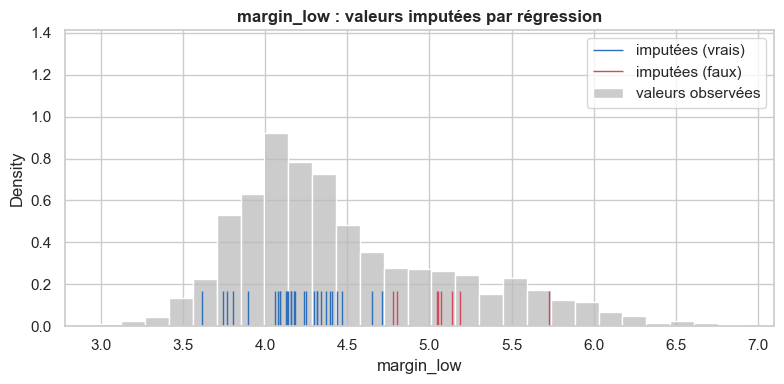

CONTRÔLE FINAL
Valeurs manquantes restantes : 0
OBJECTIF ATTEINT


In [12]:
df_clean = df.copy()
masque_nan = df_clean["margin_low"].isna()
df_clean.loc[masque_nan, "margin_low"] = modele_reg.predict(df_clean.loc[masque_nan])
df_clean["margin_low_imputee"] = masque_nan          # traçabilité : quelles valeurs ont été imputées

print(f"Valeurs imputées : min = {df_clean.loc[masque_nan, 'margin_low'].min():.2f} | "
      f"max = {df_clean.loc[masque_nan, 'margin_low'].max():.2f}  "
      f"(plage observée : {df['margin_low'].min():.2f} - {df['margin_low'].max():.2f})")

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df_clean.loc[~masque_nan, "margin_low"], stat="density", color="#bbbbbb", label="valeurs observées", ax=ax)
sns.rugplot(df_clean.loc[masque_nan & df_clean["is_genuine"], "margin_low"], color=COULEURS["Vrai"], height=0.12, lw=2, label="imputées (vrais)", ax=ax)
sns.rugplot(df_clean.loc[masque_nan & ~df_clean["is_genuine"], "margin_low"], color=COULEURS["Faux"], height=0.12, lw=2, label="imputées (faux)", ax=ax)
ax.set_title("margin_low : valeurs imputées par régression"); ax.legend()
plt.tight_layout(); plt.show()

titre("CONTRÔLE FINAL")
total_na = int(df_clean[VARIABLES].isna().sum().sum())
print(f"Valeurs manquantes restantes : {total_na}")
print("OBJECTIF ATTEINT" if total_na == 0 else "IL RESTE DES TROUS À TRAITER")

Les valeurs imputées sont cohérentes : elles restent dans la plage observée, et celles des faux billets sont globalement plus élevées que celles des vrais, comme attendu.

### 5.5  Point de méthode : éviter la « fuite de données » (data leakage)
`df_clean` sert à **l'analyse exploratoire** (Partie B). Pour la **modélisation** (Partie C), on fait mieux : on intègre l'imputation **dans le pipeline** de chaque modèle avec `IterativeImputer(estimator=LinearRegression())`.
- C'est **la même méthode** (une régression linéaire de `margin_low` sur les autres mesures) …
- … mais elle est **apprise uniquement sur le jeu d'entraînement**, puis appliquée au jeu de test : le test reste réellement « jamais vu ».
- Et surtout, le modèle sauvegardé saura **compléter lui-même** une mesure manquante en production.

Vérifions que les deux approches donnent bien les mêmes coefficients (sur l'ensemble des données) :

In [13]:
imputeur = IterativeImputer(estimator=LinearRegression(), random_state=RANDOM_STATE).fit(df[VARIABLES])
idx_ml = VARIABLES.index("margin_low")
coef_iter = imputeur.imputation_sequence_[-1].estimator.coef_
comparaison = pd.DataFrame({"statsmodels (5.1)": modele_reg.params.drop("Intercept")[["diagonal", "height_left", "height_right", "margin_up", "length"]].values,
                            "IterativeImputer": coef_iter},
                           index=["diagonal", "height_left", "height_right", "margin_up", "length"])
display(comparaison.round(4))
print("Écart maximal entre les valeurs imputées :",
      f"{np.abs(imputeur.transform(df[VARIABLES])[masque_nan.values, idx_ml] - df_clean.loc[masque_nan, 'margin_low'].values).max():.2e} mm")

,statsmodels (5.1),IterativeImputer
diagonal,-0.111,-0.111
height_left,0.184,0.184
height_right,0.257,0.257
margin_up,0.256,0.256
length,-0.409,-0.409


Écart maximal entre les valeurs imputées : 1.28e-13 mm


Coefficients identiques : l'`IterativeImputer` reproduit exactement notre régression linéaire. On peut l'utiliser en toute confiance dans les pipelines.

---
## 6. Contrôle des doublons et conformité au cahier des charges

Vérification des exigences avant de passer à l'analyse.

In [14]:
# =============================================================================
# 6. DOUBLONS ET CONFORMITÉ
# =============================================================================

titre("6.1  DOUBLONS DANS LE JEU NETTOYÉ")
print(f"Lignes strictement identiques    : {df_clean.duplicated().sum()}")
print(f"Billets aux 6 mesures identiques : {df_clean.duplicated(subset=VARIABLES).sum()}")

titre("6.2  CONFORMITÉ AU CAHIER DES CHARGES")
controles = [
    ("Nombre de billets",              len(df_clean),                          "= 1 500", len(df_clean) == 1500),
    ("Vrais billets",                  int(df_clean["is_genuine"].sum()),      "= 1 000", df_clean["is_genuine"].sum() == 1000),
    ("Faux billets",                   int((~df_clean["is_genuine"]).sum()),   "= 500",   (~df_clean["is_genuine"]).sum() == 500),
    ("Variables géométriques",         len(VARIABLES),                          "= 6",     all(v in df_clean.columns for v in VARIABLES)),
    ("Valeurs manquantes (6 mesures)", int(df_clean[VARIABLES].isna().sum().sum()), "= 0", df_clean[VARIABLES].isna().sum().sum() == 0),
    ("Doublons",                       int(df_clean.duplicated(subset=VARIABLES).sum()), "= 0", df_clean.duplicated(subset=VARIABLES).sum() == 0),
]
bilan = pd.DataFrame(controles, columns=["Contrôle", "Valeur", "Exigence", "OK"])
bilan["Statut"] = np.where(bilan["OK"], "CONFORME", "NON CONFORME")
display(bilan.drop(columns="OK"))

6.1  DOUBLONS DANS LE JEU NETTOYÉ
Lignes strictement identiques    : 0
Billets aux 6 mesures identiques : 0
6.2  CONFORMITÉ AU CAHIER DES CHARGES


,Contrôle,Valeur,Exigence,Statut
0,Nombre de billets,1500,= 1 500,CONFORME
1,Vrais billets,1000,= 1 000,CONFORME
2,Faux billets,500,= 500,CONFORME
3,Variables géométriques,6,= 6,CONFORME
4,Valeurs manquantes (6 mesures),0,= 0,CONFORME
5,Doublons,0,= 0,CONFORME


---
# Partie B — Analyse exploratoire

Question directrice : **quelles mesures différencient le mieux les vrais des faux billets ?** L'analyse porte sur le jeu nettoyé `df_clean` (1 500 billets, sans valeur manquante).

---
## 7. Analyse univariée

On examine **chaque variable prise isolément** : tendance centrale, dispersion, forme de la distribution.

### 7.1 Répartition vrai / faux

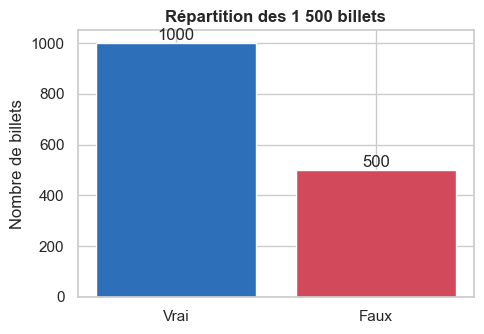

,nb_billets,pct
type,,
Vrai,1000,66.7
Faux,500,33.3


In [15]:
# =============================================================================
# 7. ANALYSE UNIVARIÉE
# =============================================================================

comptes = df_clean["type"].value_counts()[["Vrai", "Faux"]]
fig, ax = plt.subplots(figsize=(5, 3.5))
barres = ax.bar(comptes.index, comptes.values, color=[COULEURS["Vrai"], COULEURS["Faux"]])
ax.bar_label(barres)
ax.set(title="Répartition des 1 500 billets", xlabel="", ylabel="Nombre de billets")
plt.tight_layout(); plt.show()
display(comptes.to_frame("nb_billets").assign(pct=lambda t: (t.nb_billets / t.nb_billets.sum() * 100).round(1)))

### 7.2 Statistiques descriptives

In [16]:
titre("7.2  STATISTIQUES DESCRIPTIVES (en mm)")
stats_desc = df_clean[VARIABLES].describe().T
stats_desc["asymétrie"] = df_clean[VARIABLES].skew()
stats_desc["aplatissement"] = df_clean[VARIABLES].kurtosis()
stats_desc["CV %"] = (stats_desc["std"] / stats_desc["mean"] * 100)
display(stats_desc[["count", "mean", "std", "min", "25%", "50%", "75%", "max",
                    "asymétrie", "aplatissement", "CV %"]].round(3))

7.2  STATISTIQUES DESCRIPTIVES (en mm)


,count,mean,std,min,25%,50%,75%,max,asymétrie,aplatissement,CV %
diagonal,1500.0,171.958,0.305,171.04,171.75,171.96,172.17,173.01,-0.033,-0.125,0.177
height_left,1500.0,104.030,0.299,103.14,103.82,104.04,104.23,104.88,-0.092,-0.195,0.288
height_right,1500.0,103.920,0.326,102.82,103.71,103.92,104.15,104.95,-0.000,-0.027,0.313
margin_low,1500.0,4.483,0.660,2.98,4.02,4.31,4.87,6.90,0.871,0.255,14.713
margin_up,1500.0,3.151,0.232,2.27,2.99,3.14,3.31,3.91,0.146,-0.245,7.356
length,1500.0,112.678,0.873,109.49,112.03,112.96,113.34,114.44,-0.816,-0.280,0.775


> **Comment lire ce tableau**
>
> - **écart moyenne / médiane (50 %)** : s'ils divergent fortement, la distribution est asymétrique
> - **asymétrie (*skewness*)** : 0 = symétrique ; > 1 = forte traîne à droite ; < −1 = traîne à gauche
> - **aplatissement (*kurtosis*, en excès)** : 0 = comme une loi normale ; > 0 = plus pointue, avec des valeurs extrêmes plus marquées
> - **CV %** : écart-type rapporté à la moyenne — dispersion relative, comparable d'une variable à l'autre

**Lecture** :
- Toutes les mesures sont **très peu dispersées** (CV ≤ 15 %) : les billets ont des dimensions très proches, les différences se jouent à quelques dixièmes de millimètre — d'où l'intérêt d'une machine.
- Les asymétries restent **faibles** (toutes entre −1 et +1) : pas de variable très déformée.
- `length` (asymétrie négative) et `margin_low` (asymétrie positive) sont les plus déformées : c'est le signe d'un **mélange de deux populations** (vrais et faux), confirmé ci-dessous.

### 7.3 Distribution de chaque mesure
Pour chaque variable : la distribution globale (avec moyenne et médiane), puis la même distribution **séparée par type de billet**. Si les deux couleurs se chevauchent peu, la variable est **discriminante**.

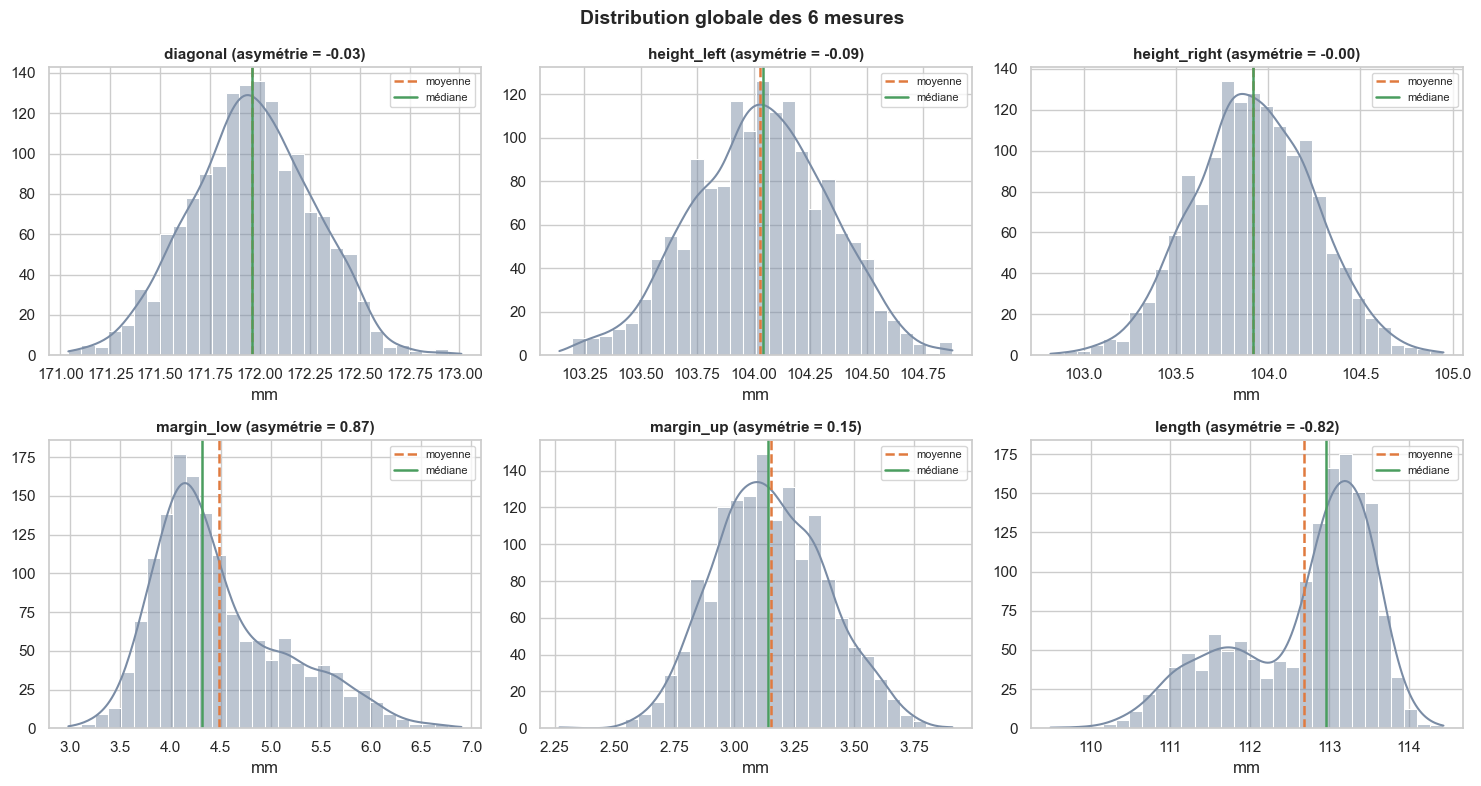

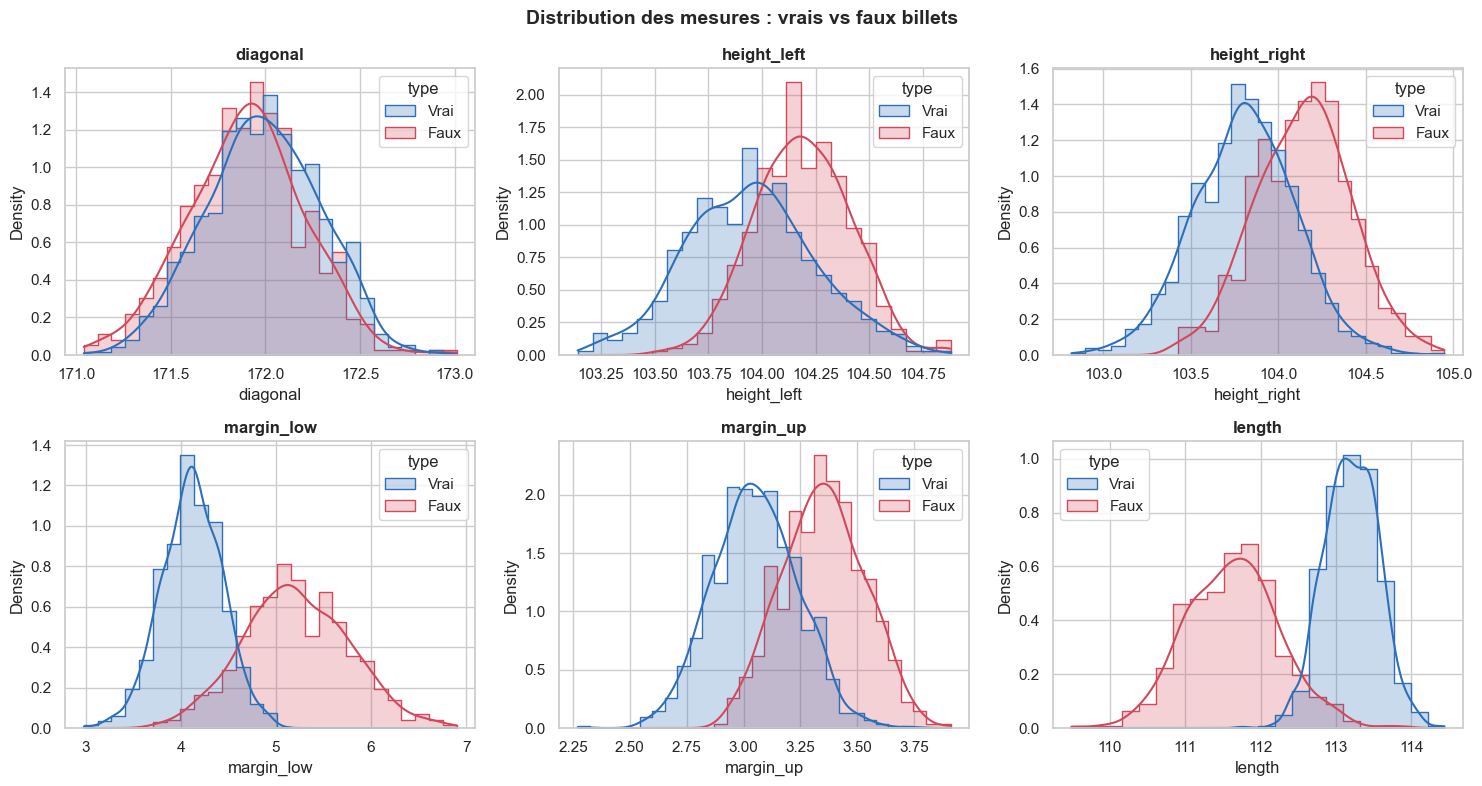

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), VARIABLES):
    sns.histplot(df_clean[col], bins=30, kde=True, ax=ax, color="#7a8ca5", edgecolor="white")
    ax.axvline(df_clean[col].mean(), color="#e07a3f", ls="--", lw=1.8, label="moyenne")
    ax.axvline(df_clean[col].median(), color="#4a9d5f", ls="-", lw=1.8, label="médiane")
    ax.set_title(f"{col} (asymétrie = {df_clean[col].skew():.2f})", fontsize=11)
    ax.set_xlabel("mm"); ax.set_ylabel(""); ax.legend(fontsize=8)
fig.suptitle("Distribution globale des 6 mesures", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, var in zip(axes.ravel(), VARIABLES):
    sns.histplot(data=df_clean, x=var, hue="type", hue_order=["Vrai", "Faux"], palette=COULEURS,
                 kde=True, stat="density", common_norm=False, element="step", ax=ax)
    ax.set_title(var)
fig.suptitle("Distribution des mesures : vrais vs faux billets", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

**Lecture** :
- `length`, `margin_low` et `margin_up` montrent **deux bosses bien séparées** une fois les types distingués → très discriminantes. La « bosse » secondaire visible sur la distribution globale de `length` (vers 111-112 mm) correspond aux faux billets.
- `height_left` et `height_right` : décalage visible mais chevauchement important.
- `diagonal` : les deux courbes se superposent presque → peu discriminante à elle seule.

### 7.4 Boîtes à moustaches des variables centrées-réduites
Les variables sont centrées-réduites **uniquement pour ce graphique**, afin de les comparer sur une même échelle (en écarts-types).

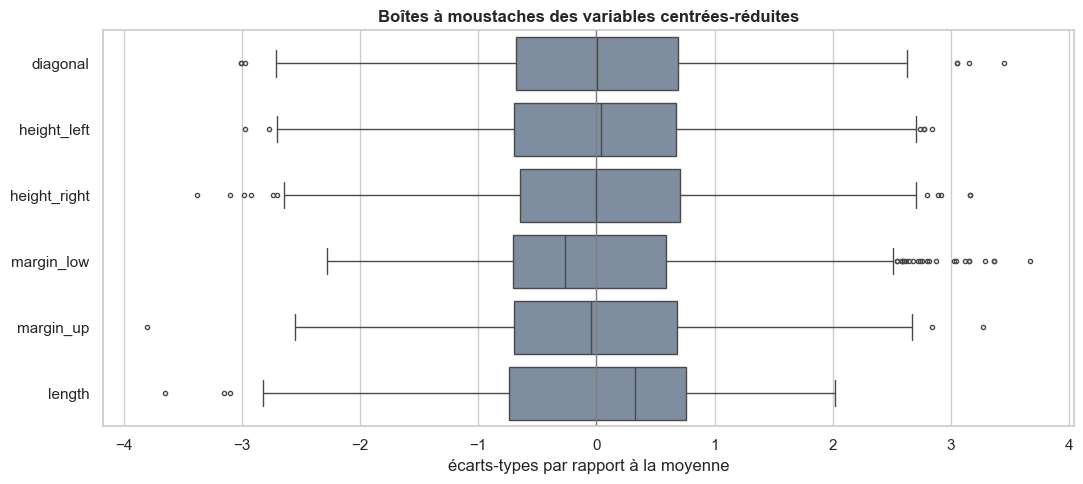

In [18]:
X_std_eda = pd.DataFrame(StandardScaler().fit_transform(df_clean[VARIABLES]), columns=VARIABLES)
plt.figure(figsize=(11, 5))
sns.boxplot(data=X_std_eda, orient="h", color="#7a8ca5", fliersize=3, linewidth=1)
plt.axvline(0, color="grey", lw=1)
plt.title("Boîtes à moustaches des variables centrées-réduites")
plt.xlabel("écarts-types par rapport à la moyenne")
plt.tight_layout(); plt.show()

---
## 8. Analyse des valeurs extrêmes (outliers)

Une valeur extrême n'est pas nécessairement une erreur. Il faut distinguer :
- l'**erreur de saisie** — à corriger ou supprimer ;
- la **valeur légitime mais atypique** — par exemple un faux billet, dont les dimensions s'écartent justement de la norme.

On les détecte par la **méthode de Tukey (écart interquartile)** : une valeur est atypique si elle sort de l'intervalle [Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR], puis on décide.

In [19]:
# =============================================================================
# 8. VALEURS EXTRÊMES
# =============================================================================

def bornes_tukey(serie, k=1.5):
    # Bornes de Tukey : au-delà de k écarts interquartiles hors des quartiles.
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

lignes = []
for col in VARIABLES:
    bas, haut = bornes_tukey(df_clean[col])
    masque = (df_clean[col] < bas) | (df_clean[col] > haut)
    lignes.append({"variable": col, "borne_basse": round(bas, 2), "borne_haute": round(haut, 2),
                   "nb_outliers": int(masque.sum()), "% du total": round(masque.mean() * 100, 1),
                   "dont faux billets": int((masque & ~df_clean["is_genuine"]).sum())})
titre("8.1  DÉTECTION PAR LA MÉTHODE DE TUKEY")
display(pd.DataFrame(lignes).set_index("variable"))

8.1  DÉTECTION PAR LA MÉTHODE DE TUKEY


,borne_basse,borne_haute,nb_outliers,% du total,dont faux billets
variable,,,,,
diagonal,171.12,172.80,7,0.5,4
height_left,103.20,104.85,6,0.4,3
height_right,103.05,104.81,11,0.7,4
margin_low,2.74,6.15,24,1.6,24
margin_up,2.51,3.79,3,0.2,2
length,110.06,115.31,3,0.2,3


8.2  VALEURS EXTRÊMES PAR TYPE DE BILLET


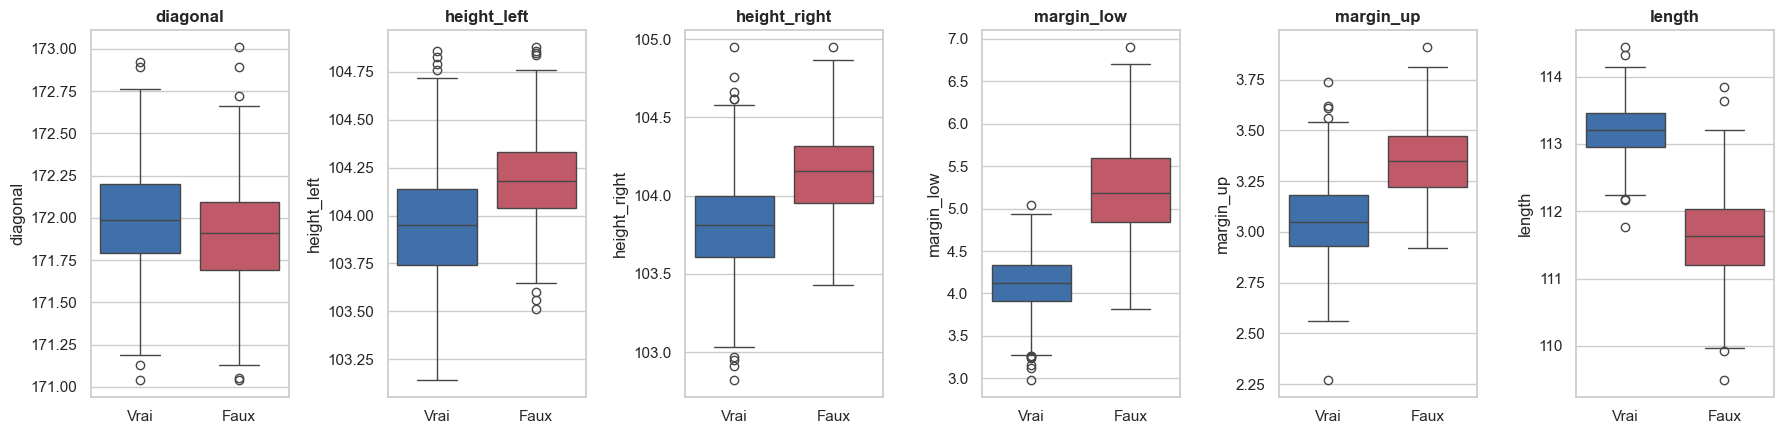

Valeurs absurdes (<= 0) : 0
Asymétrie maximale (en valeur absolue) : 0.87


In [20]:
titre("8.2  VALEURS EXTRÊMES PAR TYPE DE BILLET")
fig, axes = plt.subplots(1, 6, figsize=(18, 4.5))
for ax, var in zip(axes, VARIABLES):
    sns.boxplot(data=df_clean, x="type", y=var, order=["Vrai", "Faux"], palette=COULEURS, ax=ax)
    ax.set(title=var, xlabel="")
plt.tight_layout(); plt.show()

print("Valeurs absurdes (<= 0) :", int((df_clean[VARIABLES] <= 0).sum().sum()))
print("Asymétrie maximale (en valeur absolue) :", f"{df_clean[VARIABLES].skew().abs().max():.2f}")

> ### Décision méthodologique : on **conserve** les valeurs extrêmes
>
> **Pourquoi ?**
> - Ce sont des **mesures physiques plausibles** (quelques dixièmes de millimètre d'écart), pas des erreurs de saisie : aucune valeur nulle, négative ou aberrante (§4.3).
> - Ces outliers « globaux » sont souvent des **faux billets** (colonne « dont faux billets ») : les supprimer reviendrait à supprimer l'information que l'on cherche à apprendre.
> - Les outliers sont rares : au plus 1,6 % des billets selon la variable (`margin_low`), et **la majorité sont des faux billets** (tous ceux de `margin_low`).
>
> **Faut-il les transformer (logarithme) ?** Non. Une transformation log sert à comprimer des variables **très asymétriques** (asymétrie > 2, comme des populations ou des PIB). Ici, toutes les asymétries sont **inférieures à 1** en valeur absolue : aucune transformation n'est nécessaire. La **standardisation** utilisée avant la modélisation suffit à mettre les variables sur la même échelle.

---
## 9. Analyse bivariée

On étudie maintenant les **relations entre variables**. Trois objectifs :
1. **trouver les variables liées à la cible** (vrai / faux) — ce sont elles qui permettront de prédire ;
2. **détecter les redondances** entre mesures — deux variables très corrélées portent la même information ;
3. **anticiper l'ACP** et la modélisation.

### 9.1 Matrice de corrélation
On encode `is_genuine` en 0/1 (1 = vrai) pour l'inclure : sa corrélation de Pearson avec une mesure est la **corrélation point-bisériale**.

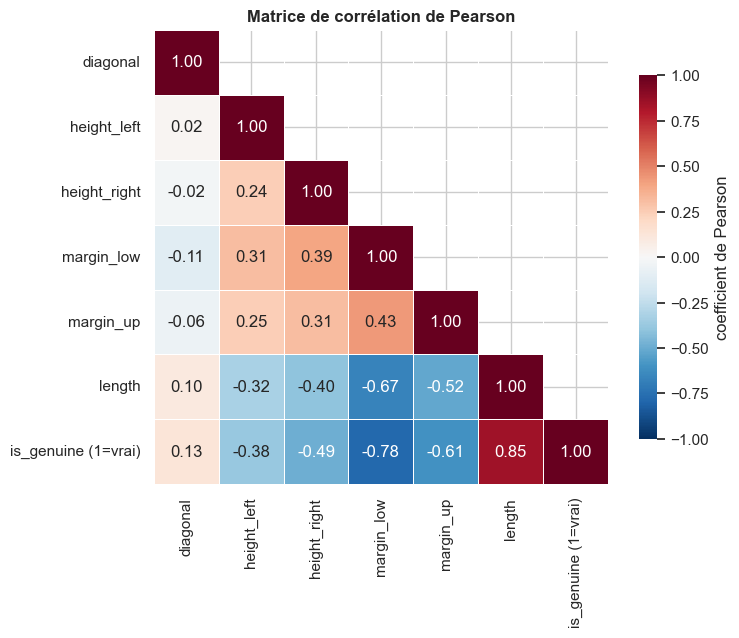

In [21]:
# =============================================================================
# 9. ANALYSE BIVARIÉE
# =============================================================================

df_corr = df_clean[VARIABLES].copy()
df_corr["is_genuine (1=vrai)"] = df_clean["is_genuine"].astype(int)
matrice = df_corr.corr()

masque_triangle = np.triu(np.ones_like(matrice, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(matrice, mask=masque_triangle, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=.5, cbar_kws={"shrink": .8, "label": "coefficient de Pearson"}, ax=ax)
ax.set_title("Matrice de corrélation de Pearson")
plt.tight_layout(); plt.show()

### 9.2 Corrélation de chaque mesure avec la cible

In [22]:
def intensite(r):
    a = abs(r)
    if a >= 0.8: return "très forte"
    if a >= 0.6: return "forte"
    if a >= 0.4: return "modérée"
    if a >= 0.2: return "faible"
    return "négligeable"

titre("9.2  CORRÉLATION AVEC LE FAIT D'ÊTRE UN VRAI BILLET")
cible = (matrice["is_genuine (1=vrai)"].drop("is_genuine (1=vrai)")
         .sort_values(key=abs, ascending=False).to_frame("r"))
cible["intensité"] = cible["r"].apply(intensite)
cible["sens"] = np.where(cible["r"] > 0, "plus grand → plutôt VRAI", "plus grand → plutôt FAUX")
display(cible.round(3))

9.2  CORRÉLATION AVEC LE FAIT D'ÊTRE UN VRAI BILLET


,r,intensité,sens
length,0.849,très forte,plus grand → plutôt VRAI
margin_low,-0.783,forte,plus grand → plutôt FAUX
margin_up,-0.606,forte,plus grand → plutôt FAUX
height_right,-0.485,modérée,plus grand → plutôt FAUX
height_left,-0.380,faible,plus grand → plutôt FAUX
diagonal,0.133,négligeable,plus grand → plutôt VRAI


**Lecture** :
- `length` (r ≈ +0,85) : plus un billet est **long**, plus il a de chances d'être vrai.
- `margin_low` (r ≈ −0,78) et `margin_up` (r ≈ −0,61) : plus les **marges sont grandes**, plus il a de chances d'être faux.
- `height_right` et `height_left` : corrélation négative modérée / faible.
- `diagonal` (r ≈ +0,13) : lien négligeable.

C'est l'indice du notebook : *les variables corrélées à l'objectif* — `length`, `margin_low`, `margin_up` — seront les plus utiles aux modèles.

### 9.3 Les corrélations entre mesures (redondances)

In [23]:
corr_mesures = df_clean[VARIABLES].corr()
paires = (corr_mesures.where(np.triu(np.ones(corr_mesures.shape), k=1).astype(bool))
          .stack().dropna().reset_index())
paires.columns = ["variable_1", "variable_2", "correlation"]
paires["|r|"] = paires["correlation"].abs()
paires["intensité"] = paires["correlation"].apply(intensite)
paires["sens"] = np.where(paires["correlation"] > 0, "positive", "négative")

titre("9.3  CORRÉLATIONS ENTRE MESURES (de la plus forte à la plus faible)")
display(paires.sort_values("|r|", ascending=False)[["variable_1", "variable_2", "correlation", "intensité", "sens"]]
        .reset_index(drop=True).round(3))
print(f"Paires quasi redondantes (|r| > 0,9) : {int((paires['|r|'] > 0.9).sum())}")

9.3  CORRÉLATIONS ENTRE MESURES (de la plus forte à la plus faible)


,variable_1,variable_2,correlation,intensité,sens
0,margin_low,length,-0.671,forte,négative
1,margin_up,length,-0.521,modérée,négative
2,margin_low,margin_up,0.434,modérée,positive
3,height_right,length,-0.402,modérée,négative
4,height_right,margin_low,0.394,faible,positive
5,height_left,length,-0.321,faible,négative
6,height_left,margin_low,0.309,faible,positive
7,height_right,margin_up,0.307,faible,positive
8,height_left,margin_up,0.247,faible,positive
9,height_left,height_right,0.242,faible,positive


Paires quasi redondantes (|r| > 0,9) : 0


**Lecture** : aucune paire n'est redondante (toutes |r| < 0,9). La plus forte, `margin_low` / `length` (r ≈ −0,67), s'explique par la cible : les faux billets sont **à la fois** plus courts et à plus grandes marges. Les 6 mesures apportent donc chacune une part d'information propre ; on le confirmera avec le **VIF** et l'ACP.

### 9.4 Vue croisée (pairplot)
Chaque nuage de points croise deux mesures. On visualise si les deux groupes forment des **paquets séparés**.

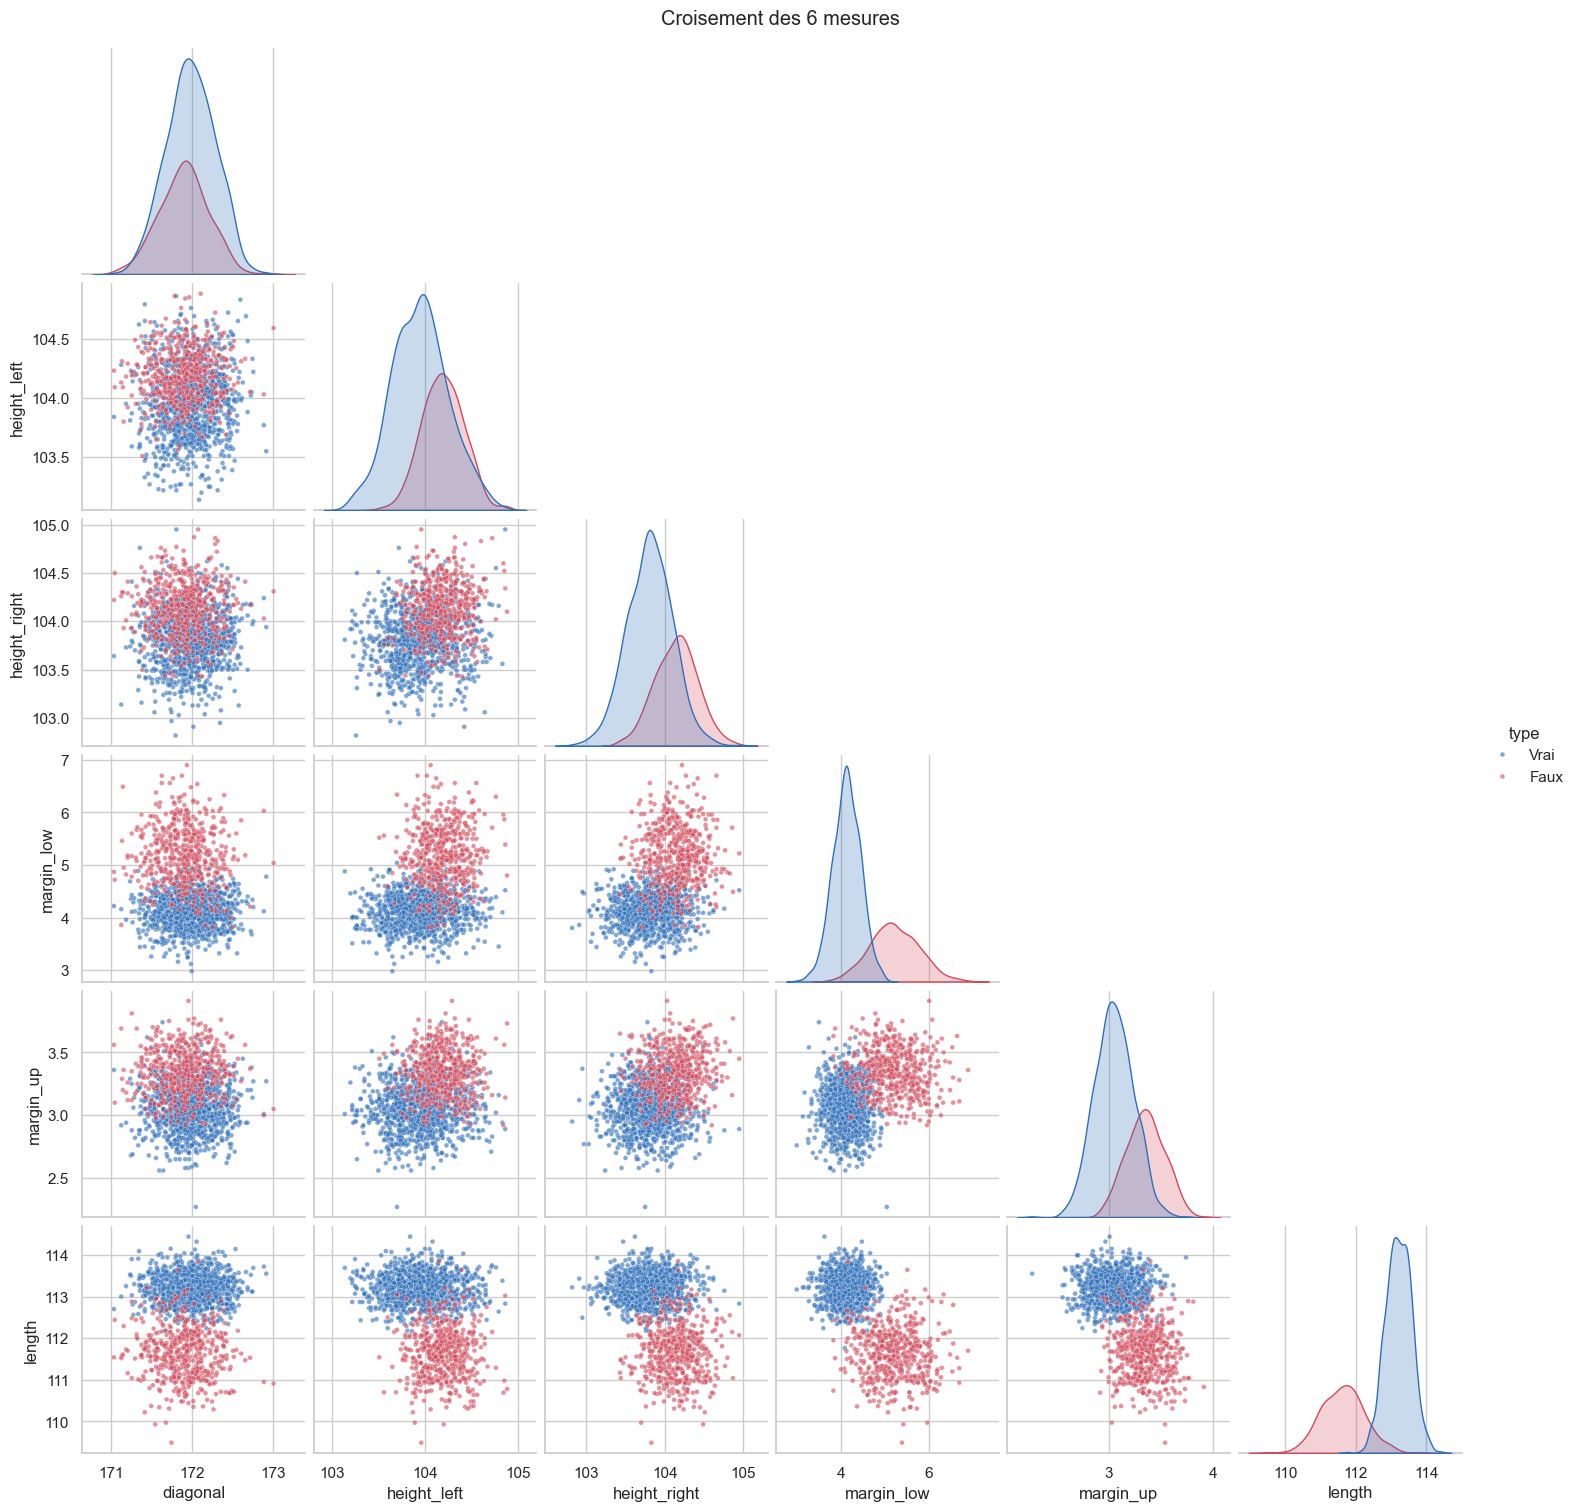

In [24]:
g = sns.pairplot(df_clean[VARIABLES + ["type"]], hue="type", hue_order=["Vrai", "Faux"],
                 palette=COULEURS, corner=True, plot_kws={"s": 12, "alpha": 0.6})
g.fig.suptitle("Croisement des 6 mesures", y=1.01)
plt.show()

**Lecture** : le croisement `margin_low` × `length` sépare presque parfaitement les deux groupes. Les deux classes sont donc **quasi linéairement séparables**, un signal fort qu'un modèle simple comme la **régression logistique** pourra très bien fonctionner.

### 9.5 Analyse avec la variable qualitative : les différences vrai / faux sont-elles significatives ?
Pour chaque mesure, on compare les vrais et les faux billets.
- **H0** : les deux groupes ont la même distribution.
- On utilise le **test de Mann-Whitney** (non paramétrique : il ne suppose pas la normalité) et, en complément, le **test t de Welch** (compare les moyennes sans supposer des variances égales).
- Seuil de décision : **α = 5 %**. Si p-value < 0,05 → on rejette H0 → la différence est significative.

In [25]:
resultats = []
for var in VARIABLES:
    vrais = df_clean.loc[df_clean["is_genuine"], var]
    faux = df_clean.loc[~df_clean["is_genuine"], var]
    p_mw = stats.mannwhitneyu(vrais, faux, alternative="two-sided").pvalue
    p_t = stats.ttest_ind(vrais, faux, equal_var=False).pvalue
    resultats.append({"variable": var, "moyenne vrais": vrais.mean(), "moyenne faux": faux.mean(),
                      "écart (faux - vrai)": faux.mean() - vrais.mean(),
                      "p-value Mann-Whitney": p_mw, "p-value Welch": p_t,
                      "significatif (5 %)": "oui" if p_mw < 0.05 else "non"})
tests = pd.DataFrame(resultats).set_index("variable")
display(tests.style.format({"moyenne vrais": "{:.3f}", "moyenne faux": "{:.3f}", "écart (faux - vrai)": "{:+.3f}",
                            "p-value Mann-Whitney": "{:.2e}", "p-value Welch": "{:.2e}"}))

,moyenne vrais,moyenne faux,écart (faux - vrai),p-value Mann-Whitney,p-value Welch,significatif (5 %)
variable,,,,,,
diagonal,171.987,171.901,-0.086,5.85e-07,3.19e-07,oui
height_left,103.949,104.190,+0.241,4.88e-53,1.42e-61,oui
height_right,103.809,104.144,+0.335,4.81e-81,9.29e-89,oui
margin_low,4.118,5.214,+1.096,2.19e-186,6.55e-186,oui
margin_up,3.052,3.350,+0.298,5.42e-123,2.93e-141,oui
length,113.202,111.631,-1.572,1.29e-205,1.47e-241,oui


**Conclusion** :
- Les faux billets sont en moyenne **plus courts** (≈ 1,6 mm de moins), avec des **marges plus grandes** (`margin_low` ≈ +1,1 mm, `margin_up` ≈ +0,3 mm) et des **hauteurs légèrement plus grandes**.
- Les **6 écarts sont significatifs** (toutes les p-values < 0,05), y compris pour `diagonal`, mais pour cette dernière l'écart moyen est minime (< 0,1 mm) : significatif statistiquement grâce aux 1 500 billets, **peu utile seul** pour discriminer.

---
## 10. Analyse en composantes principales (ACP)

L'ACP résume les 6 mesures en quelques **axes** (composantes) qui conservent un maximum d'information (variance). Elle permet de **visualiser en 2D** des données qui ont 6 dimensions.
Les données doivent d'abord être **centrées-réduites** (sinon `length`, la plus dispersée, dominerait).

### 10.1 Éboulis, cercle des corrélations et projection des billets

,variance expliquée (%),cumul (%),valeur propre
F1,43.29,43.29,2.60
F2,16.96,60.24,1.02
F3,13.03,73.27,0.78
F4,11.82,85.09,0.71
F5,9.60,94.70,0.58
F6,5.30,100.00,0.32


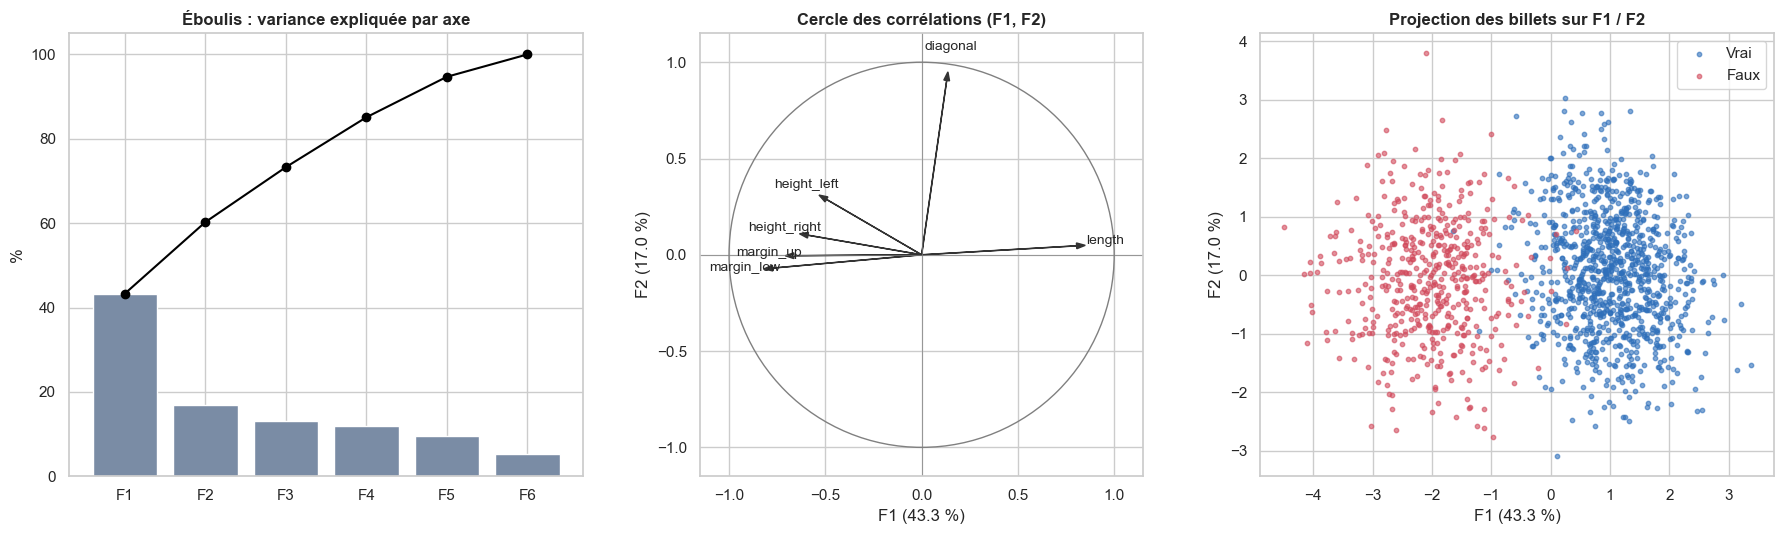

In [26]:
# =============================================================================
# 10. ACP
# =============================================================================

X_acp = StandardScaler().fit_transform(df_clean[VARIABLES])
acp = PCA(n_components=6).fit(X_acp)

inertie = pd.DataFrame({"variance expliquée (%)": acp.explained_variance_ratio_ * 100,
                        "cumul (%)": acp.explained_variance_ratio_.cumsum() * 100,
                        "valeur propre": acp.explained_variance_},
                       index=[f"F{i+1}" for i in range(6)])
display(inertie.round(2))

coords = acp.transform(X_acp)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# (a) éboulis des valeurs propres
axes[0].bar(inertie.index, inertie["variance expliquée (%)"], color="#7a8ca5")
axes[0].plot(inertie.index, inertie["cumul (%)"], "o-", color="black")
axes[0].set(title="Éboulis : variance expliquée par axe", ylabel="%")

# (b) cercle des corrélations
axes[1].add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
correl = acp.components_[:2].T * np.sqrt(acp.explained_variance_[:2])
for (x, y), var in zip(correl, VARIABLES):
    axes[1].arrow(0, 0, x, y, head_width=0.03, color="#333", length_includes_head=True)
    axes[1].text(x * 1.12, y * 1.12, var, ha="center", fontsize=10)
axes[1].axhline(0, color="grey", lw=0.5); axes[1].axvline(0, color="grey", lw=0.5)
axes[1].set(xlim=(-1.15, 1.15), ylim=(-1.15, 1.15), aspect="equal",
            title="Cercle des corrélations (F1, F2)",
            xlabel=f"F1 ({inertie.iloc[0, 0]:.1f} %)", ylabel=f"F2 ({inertie.iloc[1, 0]:.1f} %)")

# (c) projection des billets
for t in ["Vrai", "Faux"]:
    m = (df_clean["type"] == t).values
    axes[2].scatter(coords[m, 0], coords[m, 1], s=10, alpha=0.6, c=COULEURS[t], label=t)
axes[2].set(title="Projection des billets sur F1 / F2",
            xlabel=f"F1 ({inertie.iloc[0, 0]:.1f} %)", ylabel=f"F2 ({inertie.iloc[1, 0]:.1f} %)")
axes[2].legend()
plt.tight_layout(); plt.show()

### 10.2 Qualité de représentation et contributions

- La **contribution d'une variable** à un axe mesure son poids dans la construction de cet axe (en %, somme = 100 % par axe). Elle dit **quelles mesures fabriquent l'axe**.
- Le **cos²** d'un billet sur le plan F1-F2 mesure la **qualité de sa représentation** : proche de 1, sa position sur le graphique est fidèle ; proche de 0, elle n'est pas interprétable.

In [27]:
# Contributions des variables aux axes (%)
contrib_var = pd.DataFrame((acp.components_[:3].T ** 2) * 100, index=VARIABLES, columns=["F1 %", "F2 %", "F3 %"])
# Corrélations variables-axes (coordonnées sur le cercle)
correl_var = pd.DataFrame(acp.components_[:3].T * np.sqrt(acp.explained_variance_[:3]), index=VARIABLES,
                          columns=["corr F1", "corr F2", "corr F3"])
titre("10.2  CONTRIBUTIONS ET CORRÉLATIONS DES VARIABLES AUX AXES")
display(pd.concat([contrib_var, correl_var], axis=1).round(2))
print(f"Contribution moyenne attendue si toutes les variables pesaient pareil : {100 / len(VARIABLES):.1f} %")

# cos² des billets sur le plan F1-F2
cos2_F1F2 = (coords[:, :2] ** 2).sum(axis=1) / (coords ** 2).sum(axis=1)
print(f"\ncos² moyen des billets sur le plan F1-F2 : {cos2_F1F2.mean():.2f}")
display(pd.Series(cos2_F1F2).groupby(df_clean["type"].values).mean().rename("cos² moyen F1-F2").round(2).to_frame())

10.2  CONTRIBUTIONS ET CORRÉLATIONS DES VARIABLES AUX AXES


,F1 %,F2 %,F3 %,corr F1,corr F2,corr F3
diagonal,0.72,88.61,8.29,0.14,0.95,-0.25
height_left,10.93,9.46,78.33,-0.53,0.31,0.78
height_right,15.49,1.17,2.68,-0.63,0.11,-0.14
margin_low,25.78,0.52,1.19,-0.82,-0.07,-0.10
margin_up,19.31,0.00,7.30,-0.71,-0.00,-0.24
length,27.78,0.24,2.22,0.85,0.05,0.13


Contribution moyenne attendue si toutes les variables pesaient pareil : 16.7 %

cos² moyen des billets sur le plan F1-F2 : 0.57


,cos² moyen F1-F2
Faux,0.67
Vrai,0.52


### 10.3 Interprétation des axes

- **F1** (≈ 43 % de l'information à lui seul) est construit surtout par `length` (d'un côté) et `margin_low`, `margin_up` et les hauteurs (de l'autre) : c'est l'**axe « vrai ↔ faux »**. Un billet à droite est long avec de petites marges (profil vrai) ; à gauche, court avec de grandes marges (profil faux).
- **F2** (≈ 17 %) est porté presque uniquement par `diagonal` : une information indépendante des autres mesures… et qui ne sépare pas les deux types de billets.
- **Projection** : les deux groupes se séparent **presque uniquement le long de F1**. Le plan F1-F2 ne résume qu'environ 60 % de l'information : le cos² moyen indique que les positions individuelles sont à interpréter avec prudence, mais la séparation vrai / faux, elle, est nette.

**Conséquences pour la suite** : les billets forment **deux groupes naturels** (ce qui justifie d'essayer un **K-means à 2 clusters**, §13.4), séparables par une frontière quasi linéaire (ce qui favorise la **régression logistique**).

---
## 11. Export du jeu de données nettoyé

Le jeu nettoyé est exporté avec son **dictionnaire des variables**, pour la traçabilité. La modélisation (Partie C) repart cependant du fichier **brut** : l'imputation y est refaite **dans le pipeline**, sur le seul jeu d'entraînement (§5.5).

In [28]:
# =============================================================================
# 11. EXPORT
# =============================================================================

COLONNES_FINALES = ["is_genuine"] + VARIABLES + ["margin_low_imputee"]
df_final = df_clean[COLONNES_FINALES]
df_final.to_csv(FICHIER_NETTOYE, index=False, sep=";", encoding="utf-8")

dictionnaire = pd.DataFrame([
    ("is_genuine", "nature du billet (True = vrai, False = faux)", "booléen", "ONCFM"),
    ("diagonal", "diagonale du billet", "mm", "ONCFM"),
    ("height_left", "hauteur mesurée sur le côté gauche", "mm", "ONCFM"),
    ("height_right", "hauteur mesurée sur le côté droit", "mm", "ONCFM"),
    ("margin_low", "marge entre le bord inférieur et l'image (37 valeurs imputées par régression linéaire)", "mm", "ONCFM + imputation"),
    ("margin_up", "marge entre le bord supérieur et l'image", "mm", "ONCFM"),
    ("length", "longueur du billet", "mm", "ONCFM"),
    ("margin_low_imputee", "True si margin_low a été imputée", "booléen", "CRÉÉE"),
], columns=["variable", "description", "unité", "source"])
dictionnaire.to_csv(FICHIER_DICTIONNAIRE, index=False, sep=";", encoding="utf-8")

titre("11.  EXPORT RÉALISÉ")
print(f"Fichier nettoyé : {FICHIER_NETTOYE}  ({df_final.shape[0]} billets x {df_final.shape[1]} colonnes)")
print(f"Dictionnaire    : {FICHIER_DICTIONNAIRE}")
print(f"Valeurs manquantes dans le fichier exporté : {int(df_final.isna().sum().sum())}")
display(dictionnaire)

11.  EXPORT RÉALISÉ
Fichier nettoyé : billets_nettoyes.csv  (1500 billets x 8 colonnes)
Dictionnaire    : dictionnaire_variables.csv
Valeurs manquantes dans le fichier exporté : 0


,variable,description,unité,source
0,is_genuine,"nature du billet (True = vrai, False = faux)",booléen,ONCFM
1,diagonal,diagonale du billet,mm,ONCFM
2,height_left,hauteur mesurée sur le côté gauche,mm,ONCFM
3,height_right,hauteur mesurée sur le côté droit,mm,ONCFM
4,margin_low,marge entre le bord inférieur et l'image (37 v...,mm,ONCFM + imputation
5,margin_up,marge entre le bord supérieur et l'image,mm,ONCFM
6,length,longueur du billet,mm,ONCFM
7,margin_low_imputee,True si margin_low a été imputée,booléen,CRÉÉE


---
# Partie C — Modélisation et application

---
## 12. Prétraitement

Le but est de transformer les données brutes en données que les algorithmes de Machine Learning peuvent exploiter efficacement.

### 12.1 Séparer les variables explicatives (X) et la cible (y)
- **X** = les 6 mesures du billet (dans l'ordre du cahier des charges).
- **y** = la cible. On code **1 = FAUX billet**, **0 = vrai billet**, car c'est le faux billet que l'on veut détecter (classe « positive »).

Pourquoi ? Le modèle apprend à prédire y à partir de X. Avec ce codage, le **rappel (recall)** mesure directement « la part des faux billets que l'on a réussi à attraper ».

In [29]:
X = df[VARIABLES]                               # les 6 mesures (margin_low contient encore ses NaN : le pipeline les traitera)
y = (~df["is_genuine"]).astype(int)              # 1 = faux billet, 0 = vrai billet
y.name = "faux"
print("X :", X.shape, "| y :", y.shape)
print(y.value_counts().rename({0: "0 = vrai", 1: "1 = faux"}))

X : (1500, 6) | y : (1500,)
faux
0 = vrai    1000
1 = faux     500
Name: count, dtype: int64


### 12.2 Séparer les données d'entraînement (train) et de test
- **75 % train** (1 125 billets) pour apprendre et régler les modèles, **25 % test** (375 billets) mis de côté pour l'évaluation finale.
- `stratify=y` : on conserve la proportion 2/3 vrais – 1/3 faux dans les deux jeux.
- `random_state=42` : découpage reproductible.

Pourquoi ? Pour juger le modèle sur des billets **qu'il n'a jamais vus** et détecter le sur-apprentissage (un modèle qui apprend « par cœur » sans savoir généraliser).

**Et le réglage des hyperparamètres ?** Il se fait par **validation croisée à 5 plis sur le train uniquement** (`GridSearchCV`). Le jeu de test n'est utilisé **qu'une seule fois**, à la fin, pour comparer les modèles.

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

print(f"Train : {X_train.shape[0]} billets  ({y_train.sum()} faux, soit {y_train.mean():.1%})")
print(f"Test  : {X_test.shape[0]} billets  ({y_test.sum()} faux, soit {y_test.mean():.1%})")
print("Valeurs manquantes -> train :", X_train['margin_low'].isna().sum(), "| test :", X_test['margin_low'].isna().sum())

Train : 1125 billets  (375 faux, soit 33.3%)
Test  : 375 billets  (125 faux, soit 33.3%)
Valeurs manquantes -> train : 26 | test : 11


### 12.3 Mettre toutes les variables sur la même échelle (standardisation)
`StandardScaler` transforme chaque variable pour avoir **moyenne = 0 et écart-type = 1**.

Pourquoi ? Le **KNN** (calcul de distances), la **régression logistique** (régularisation) et le **K-means** (distances aux centroïdes) sont sensibles aux échelles : sans standardisation, la variable la plus dispersée (`length`, écart-type ≈ 0,87 mm) pèserait davantage que `margin_up` (≈ 0,23 mm).

Le scaler est **ajusté sur le train** (`fit`) puis **appliqué** au train et au test (`transform`) : jamais de `fit` sur le test.
Démonstration ci-dessous ; ensuite, ces étapes seront intégrées dans des **pipelines** (imputation → standardisation → modèle) pour qu'elles soient toujours appliquées dans le bon ordre.

In [31]:
imputeur_demo = IterativeImputer(estimator=LinearRegression(), random_state=RANDOM_STATE)
scaler = StandardScaler()

X_train_imp = imputeur_demo.fit_transform(X_train)     # fit sur le TRAIN uniquement
X_test_imp = imputeur_demo.transform(X_test)            # simple application au test

X_train_scaled = scaler.fit_transform(X_train_imp)      # fit sur le TRAIN uniquement
X_test_scaled = scaler.transform(X_test_imp)

display(pd.DataFrame(X_train_scaled, columns=VARIABLES).describe().loc[["mean", "std"]].round(3))

,diagonal,height_left,height_right,margin_low,margin_up,length
mean,0.0,0.0,-0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


Après standardisation, chaque variable du train a une moyenne de 0 et un écart-type de 1.

---
## 13. Modélisation

#### Méthode commune aux 3 modèles supervisés
1. Construire un **pipeline** : `IterativeImputer` → `StandardScaler` → modèle.
2. Chercher les meilleurs **hyperparamètres** par `GridSearchCV` (validation croisée stratifiée à 5 plis, **sur le train**). Critère d'optimisation : le **F1-score** de la classe « faux » (équilibre entre *rappel* — attraper les faux — et *précision* — ne pas accuser les vrais à tort). Optimiser le rappel seul serait piégeux : un modèle qui dit « faux » pour tout billet aurait un rappel parfait de 100 %.
3. Évaluer **une seule fois** sur le jeu de test : matrice de confusion + métriques.

#### Rappel des métriques (classe positive = faux billet)
| Métrique | Formule | Question à laquelle elle répond |
|---|---|---|
| **Rappel (recall / sensibilité)** | TP / (TP + FN) | Parmi les faux billets, combien en a-t-on détecté ? → **critère n°1 de l'ONCFM** |
| **Précision** | TP / (TP + FP) | Quand on dit « faux », a-t-on raison ? |
| **F1-score** | moyenne harmonique précision / rappel | Compromis entre les deux |
| **Accuracy** | (TP + TN) / total | Taux global de bonnes réponses (trompeur si classes déséquilibrées) |
| **AUC ROC** | aire sous la courbe ROC | Capacité à bien **classer les probabilités** (1 = parfait, 0,5 = hasard) |

In [32]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def creer_pipeline(modele):
    # Imputation de margin_low par régression linéaire -> standardisation -> modèle
    return make_pipeline(IterativeImputer(estimator=LinearRegression(), random_state=RANDOM_STATE),
                         StandardScaler(),
                         modele)

resultats_test = {}      # stocke les métriques de test de chaque modèle
predictions_test = {}    # stocke les prédictions (pour les matrices de confusion)
probas_test = {}         # stocke les probabilités (pour les courbes ROC)

def evaluer(nom, y_vrai, y_pred, proba=None):
    # Calcule, affiche et mémorise les métriques d'un modèle sur le jeu de test.
    tn, fp, fn, tp = confusion_matrix(y_vrai, y_pred).ravel()
    res = {"Accuracy": accuracy_score(y_vrai, y_pred),
           "Rappel (faux détectés)": recall_score(y_vrai, y_pred),
           "Précision": precision_score(y_vrai, y_pred),
           "F1": f1_score(y_vrai, y_pred),
           "AUC ROC": roc_auc_score(y_vrai, proba) if proba is not None else np.nan,
           "FN (faux non détectés)": fn, "FP (vrais accusés à tort)": fp}
    resultats_test[nom] = res
    predictions_test[nom] = y_pred
    if proba is not None:
        probas_test[nom] = proba

    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    ConfusionMatrixDisplay.from_predictions(y_vrai, y_pred, display_labels=["Vrai", "Faux"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set(title=f"{nom} — jeu de test", xlabel="Prédiction", ylabel="Réalité"); ax.grid(False)
    plt.tight_layout(); plt.show()
    print(classification_report(y_vrai, y_pred, target_names=["Vrai (0)", "Faux (1)"], digits=3))
    print(f"→ {fn} faux billet(s) non détecté(s) (FN) | {fp} vrai(s) billet(s) accusé(s) à tort (FP)")

### 13.1 Régression logistique

**Principe** : le modèle calcule une combinaison linéaire des mesures, puis la transforme (fonction **sigmoïde**) en **probabilité** d'être un faux billet, entre 0 et 1. Si la probabilité ≥ 0,5 → « faux ».

**Hyperparamètres** :
- `C` : inverse de la force de **régularisation** (petit C = modèle plus « prudent », qui limite les coefficients extrêmes pour éviter le sur-apprentissage). On teste plusieurs valeurs.
- `max_iter=1000` : nombre maximum d'itérations de l'algorithme d'optimisation, pour plafonner le temps de calcul et garantir la convergence.

Meilleur hyperparamètre : {'logisticregression__C': 1}
F1 moyen en validation croisée (train) : 0.9866


,C,F1 moyen (CV),écart-type
0,0.01,0.969,0.009
1,0.10,0.983,0.008
2,1.00,0.987,0.009
3,10.00,0.985,0.011
4,100.00,0.985,0.011


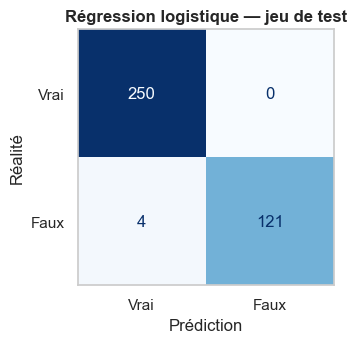

              precision    recall  f1-score   support

    Vrai (0)      0.984     1.000     0.992       250
    Faux (1)      1.000     0.968     0.984       125

    accuracy                          0.989       375
   macro avg      0.992     0.984     0.988       375
weighted avg      0.990     0.989     0.989       375

→ 4 faux billet(s) non détecté(s) (FN) | 0 vrai(s) billet(s) accusé(s) à tort (FP)


In [33]:
grille_lr = {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}
gs_lr = GridSearchCV(creer_pipeline(LogisticRegression(max_iter=1000)), grille_lr, cv=CV, scoring="f1")
gs_lr.fit(X_train, y_train)

print("Meilleur hyperparamètre :", gs_lr.best_params_)
print(f"F1 moyen en validation croisée (train) : {gs_lr.best_score_:.4f}")
display(pd.DataFrame(gs_lr.cv_results_)[["param_logisticregression__C", "mean_test_score", "std_test_score"]]
        .rename(columns={"param_logisticregression__C": "C", "mean_test_score": "F1 moyen (CV)", "std_test_score": "écart-type"}).round(4))

modele_lr = gs_lr.best_estimator_
evaluer("Régression logistique", y_test, modele_lr.predict(X_test), modele_lr.predict_proba(X_test)[:, 1])

#### Interprétation des coefficients
Comme les variables sont standardisées, les coefficients sont **comparables** entre eux : un coefficient positif augmente la probabilité d'être **faux**, un coefficient négatif la diminue.

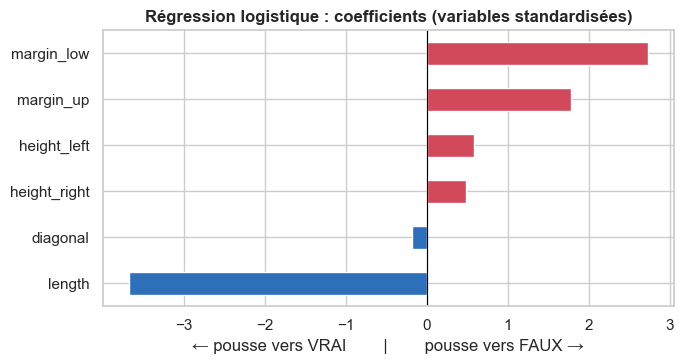

,coefficient
length,-3.679
diagonal,-0.182
height_right,0.492
height_left,0.585
margin_up,1.786
margin_low,2.732


In [34]:
coefs = pd.Series(modele_lr.named_steps["logisticregression"].coef_[0], index=VARIABLES).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.8))
coefs.plot.barh(ax=ax, color=[COULEURS["Faux"] if c > 0 else COULEURS["Vrai"] for c in coefs])
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Régression logistique : coefficients (variables standardisées)",
       xlabel="← pousse vers VRAI        |        pousse vers FAUX →")
plt.tight_layout(); plt.show()
display(coefs.to_frame("coefficient").round(3))

**Lecture** : `length` a le coefficient le plus fort (négatif : un billet long est plutôt vrai), suivi de `margin_low` et `margin_up` (positifs : de grandes marges signalent un faux). La `diagonal` a un poids quasi nul. C'est cohérent avec l'analyse exploratoire.

**Contrôle de significativité (statsmodels)** : on ajuste la même régression logistique avec statsmodels pour obtenir les **p-values** des variables (sur le train, après imputation).

In [35]:
X_train_sm = pd.DataFrame(X_train_imp, columns=VARIABLES, index=X_train.index)
logit_sm = sm.Logit(y_train, sm.add_constant(X_train_sm)).fit(disp=0)
display(pd.DataFrame({"coefficient": logit_sm.params, "p-value": logit_sm.pvalues}).round(4))

,coefficient,p-value
const,250.534,4.302e-01
diagonal,0.009,9.947e-01
height_left,2.714,7.760e-02
height_right,1.644,2.116e-01
margin_low,6.608,0.000e+00
margin_up,12.417,1.000e-04
length,-6.895,0.000e+00


**Lecture** : `length`, `margin_low` et `margin_up` sont très significatives (p < 0,001). `diagonal` (p ≈ 0,99), `height_left` et `height_right` ne sont **pas significatives** une fois les autres variables prises en compte : leur information est déjà portée par les 3 variables principales.

**Faut-il retirer ces variables ?** On teste ci-dessous trois jeux de variables en **validation croisée répétée** (5 plis × 10 répétitions = 50 évaluations, sur le train).

In [36]:
RCV = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
jeux = {"6 variables (toutes)": VARIABLES,
        "5 variables (sans diagonal)": ["height_left", "height_right", "margin_low", "margin_up", "length"],
        "3 variables (significatives)": ["margin_low", "margin_up", "length"]}
lignes = []
for nom, cols in jeux.items():
    r = cross_validate(creer_pipeline(LogisticRegression(max_iter=1000, C=gs_lr.best_params_["logisticregression__C"])),
                       X_train[cols], y_train, cv=RCV, scoring=["recall", "precision", "f1"])
    lignes.append({"jeu de variables": nom, "Rappel": r["test_recall"].mean(),
                   "Précision": r["test_precision"].mean(), "F1": r["test_f1"].mean(), "F1 écart-type": r["test_f1"].std()})
display(pd.DataFrame(lignes).set_index("jeu de variables").round(4))

,Rappel,Précision,F1,F1 écart-type
jeu de variables,,,,
6 variables (toutes),0.982,0.991,0.986,0.008
5 variables (sans diagonal),0.982,0.990,0.986,0.008
3 variables (significatives),0.978,0.992,0.985,0.008


**Décision : on conserve les 6 variables.** Les écarts entre les trois jeux sont minimes (bien inférieurs à l'écart-type du F1) : le jeu complet et le jeu à 5 variables font jeu égal, et réduire à 3 variables fait perdre un peu de rappel (0,978 contre 0,982), or le rappel est notre critère prioritaire. Garder les 6 mesures est aussi plus **simple et robuste en production** : la machine de l'ONCFM produit ces 6 mesures, et la régularisation de la régression logistique réduit déjà naturellement le poids des variables peu utiles.

### 13.2 KNN — k plus proches voisins

**Principe** : pour classer un nouveau billet, on regarde les **k billets les plus proches** (distance euclidienne sur les mesures standardisées) dans le jeu d'entraînement, et on vote à la majorité.

**Hyperparamètres** :
- `n_neighbors` (k) : trop petit → sensible au bruit (sur-apprentissage) ; trop grand → frontière trop lissée. On teste les valeurs **impaires** de 1 à 29 (impair = pas d'égalité au vote).
- `weights` : vote égal (`uniform`) ou pondéré par la proximité (`distance`).

Meilleurs hyperparamètres : {'kneighborsclassifier__n_neighbors': 3, 'kneighborsclassifier__weights': 'uniform'}
F1 moyen en validation croisée (train) : 0.9866


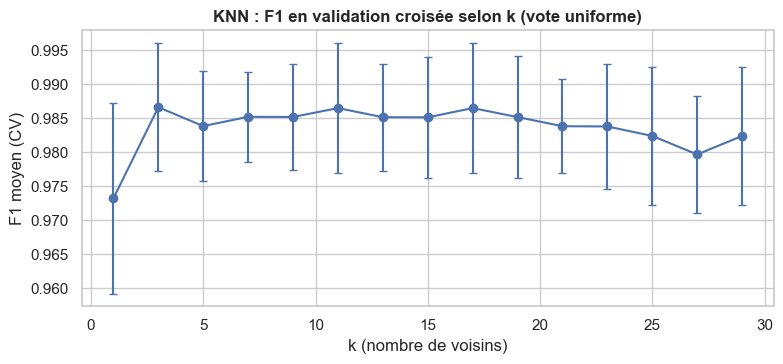

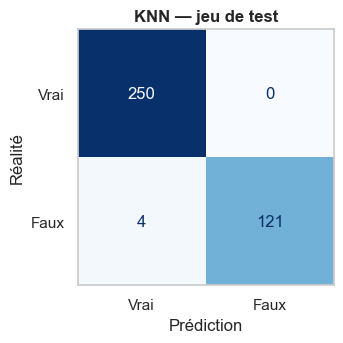

              precision    recall  f1-score   support

    Vrai (0)      0.984     1.000     0.992       250
    Faux (1)      1.000     0.968     0.984       125

    accuracy                          0.989       375
   macro avg      0.992     0.984     0.988       375
weighted avg      0.990     0.989     0.989       375

→ 4 faux billet(s) non détecté(s) (FN) | 0 vrai(s) billet(s) accusé(s) à tort (FP)


In [37]:
grille_knn = {"kneighborsclassifier__n_neighbors": list(range(1, 30, 2)),
              "kneighborsclassifier__weights": ["uniform", "distance"]}
gs_knn = GridSearchCV(creer_pipeline(KNeighborsClassifier()), grille_knn, cv=CV, scoring="f1")
gs_knn.fit(X_train, y_train)
print("Meilleurs hyperparamètres :", gs_knn.best_params_)
print(f"F1 moyen en validation croisée (train) : {gs_knn.best_score_:.4f}")

# Courbe : F1 en validation croisée selon k (vote uniforme)
cv_knn = pd.DataFrame(gs_knn.cv_results_)
courbe = cv_knn[cv_knn["param_kneighborsclassifier__weights"] == "uniform"]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(courbe["param_kneighborsclassifier__n_neighbors"].astype(int), courbe["mean_test_score"],
            yerr=courbe["std_test_score"], fmt="o-", capsize=3)
ax.set(title="KNN : F1 en validation croisée selon k (vote uniforme)", xlabel="k (nombre de voisins)", ylabel="F1 moyen (CV)")
plt.tight_layout(); plt.show()

modele_knn = gs_knn.best_estimator_
evaluer("KNN", y_test, modele_knn.predict(X_test), modele_knn.predict_proba(X_test)[:, 1])

**Lecture** : hormis **k = 1** (nettement moins bon : avec un seul voisin, le modèle colle au bruit = sur-apprentissage), la performance est **très stable** de k = 3 à k = 29 (les barres d'erreur se chevauchent) : les deux classes sont si bien séparées que le choix de k a peu d'impact. Limite du KNN : sa « probabilité » n'est que la proportion de voisins faux parmi k (valeurs très « en escalier »), et il doit conserver **tout le jeu d'entraînement** en mémoire pour prédire.

### 13.3 Random Forest — forêt aléatoire

**Principe** : on entraîne de **nombreux arbres de décision**, chacun sur un échantillon tiré au hasard (bootstrap) et en ne considérant qu'une partie des variables à chaque division. La prédiction finale est le **vote majoritaire** des arbres. Le hasard rend les arbres différents ; leur combinaison réduit le sur-apprentissage d'un arbre unique.

**Hyperparamètres** : `n_estimators` (nombre d'arbres), `max_depth` (profondeur maximale), `min_samples_leaf` (nombre minimum de billets par feuille).
*La standardisation n'est pas nécessaire pour une forêt (les arbres comparent des seuils), mais elle ne la gêne pas ; on garde le même pipeline pour comparer à l'identique.*

Meilleurs hyperparamètres : {'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__n_estimators': 300}
F1 moyen en validation croisée (train) : 0.9893


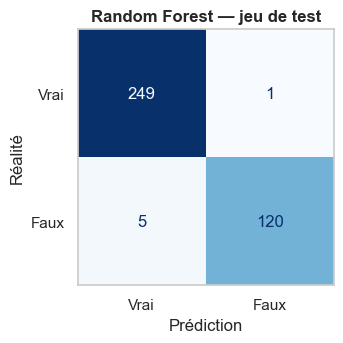

              precision    recall  f1-score   support

    Vrai (0)      0.980     0.996     0.988       250
    Faux (1)      0.992     0.960     0.976       125

    accuracy                          0.984       375
   macro avg      0.986     0.978     0.982       375
weighted avg      0.984     0.984     0.984       375

→ 5 faux billet(s) non détecté(s) (FN) | 1 vrai(s) billet(s) accusé(s) à tort (FP)


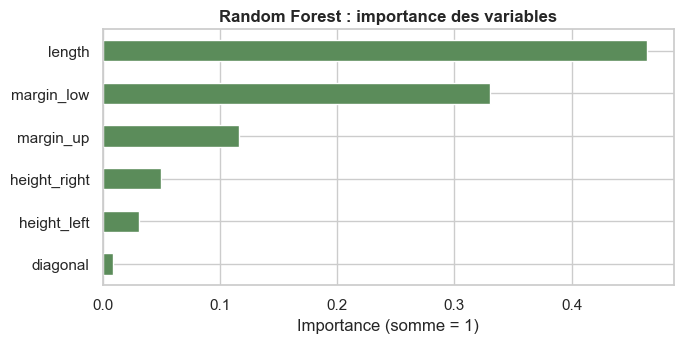

In [38]:
grille_rf = {"randomforestclassifier__n_estimators": [100, 300],
             "randomforestclassifier__max_depth": [None, 5, 10],
             "randomforestclassifier__min_samples_leaf": [1, 3]}
gs_rf = GridSearchCV(creer_pipeline(RandomForestClassifier(random_state=RANDOM_STATE)), grille_rf, cv=CV, scoring="f1")
gs_rf.fit(X_train, y_train)
print("Meilleurs hyperparamètres :", gs_rf.best_params_)
print(f"F1 moyen en validation croisée (train) : {gs_rf.best_score_:.4f}")

modele_rf = gs_rf.best_estimator_
evaluer("Random Forest", y_test, modele_rf.predict(X_test), modele_rf.predict_proba(X_test)[:, 1])

importances = pd.Series(modele_rf.named_steps["randomforestclassifier"].feature_importances_, index=VARIABLES).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
importances.plot.barh(ax=ax, color="#5b8c5a")
ax.set(title="Random Forest : importance des variables", xlabel="Importance (somme = 1)")
plt.tight_layout(); plt.show()

**Lecture** : la forêt confirme la hiérarchie trouvée par l'EDA et la régression logistique : `length` et `margin_low` dominent, puis `margin_up` ; `diagonal` est la moins utile.

### 13.4 K-means — apprentissage NON supervisé

#### En quoi est-il différent des 3 autres ?
| | Régression logistique, KNN, Random Forest | **K-means** |
|---|---|---|
| Type | **Supervisé** | **Non supervisé** |
| Utilise l'étiquette vrai/faux pour apprendre ? | Oui | **Non** : il regroupe les billets uniquement selon leurs ressemblances |
| Sortie | Une classe (vrai/faux) + probabilité | Un **numéro de cluster** (0, 1…) sans signification a priori |

#### Est-il pertinent ici ?
Oui, sous conditions : l'ACP a montré que les billets forment **deux groupes naturels**. Si K-means retrouve ces deux groupes, on peut **nommer** chaque cluster (« vrai » ou « faux ») en regardant quels billets du **train** il contient, puis classer un nouveau billet selon le **centroïde le plus proche**, c'est ce que demande le cahier des charges (« k-means, duquel seront utilisés les centroïdes pour réaliser la prédiction »).

Démarche :
1. Choisir le nombre de clusters (méthode du **coude** + **score de silhouette**), sans regarder les étiquettes.
2. Entraîner K-means (k = 2) **sur le train** (imputé + standardisé).
3. **Évaluer la forme** des clusters (silhouette, projection ACP) et les **caractériser** (mesures moyennes).
4. Associer chaque cluster à une étiquette, puis **prédire le test** par le centroïde le plus proche.

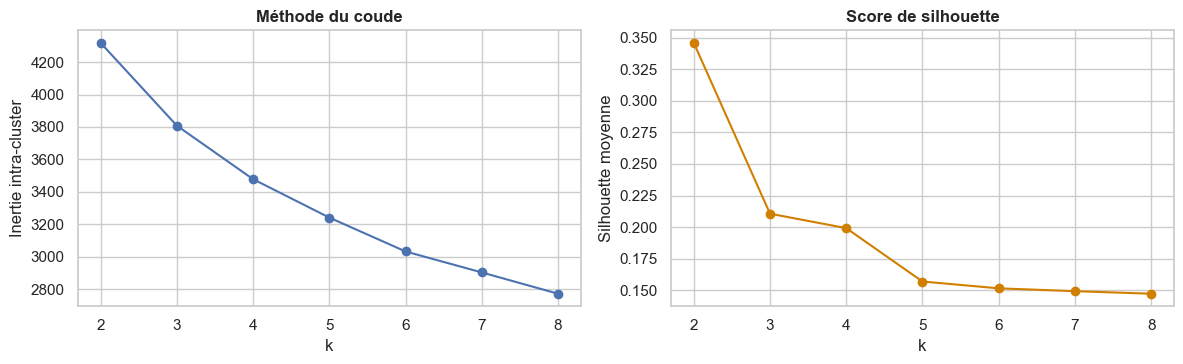

,inertie,silhouette
k,,
2,4318.559,0.346
3,3807.922,0.211
4,3477.735,0.199
5,3240.829,0.157
6,3031.849,0.152
7,2902.495,0.149
8,2771.199,0.147


In [39]:
# 1) Choix du nombre de clusters (sur le train standardisé, sans utiliser y)
inerties, silhouettes = [], []
plage_k = range(2, 9)
for k in plage_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_train_scaled)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(X_train_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(list(plage_k), inerties, "o-"); axes[0].set(title="Méthode du coude", xlabel="k", ylabel="Inertie intra-cluster")
axes[1].plot(list(plage_k), silhouettes, "o-", color="#d17f00"); axes[1].set(title="Score de silhouette", xlabel="k", ylabel="Silhouette moyenne")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"k": list(plage_k), "inertie": inerties, "silhouette": silhouettes}).set_index("k").round(3))

**Lecture** : le **score de silhouette est maximal pour k = 2** (plus il est élevé, mieux les clusters sont compacts et séparés), et la courbe d'inertie forme son coude principal à k = 2. Le choix de **2 clusters** est donc justifié par les données elles-mêmes et il correspond aux deux types de billets.

Silhouette moyenne (k=2) : 0.346


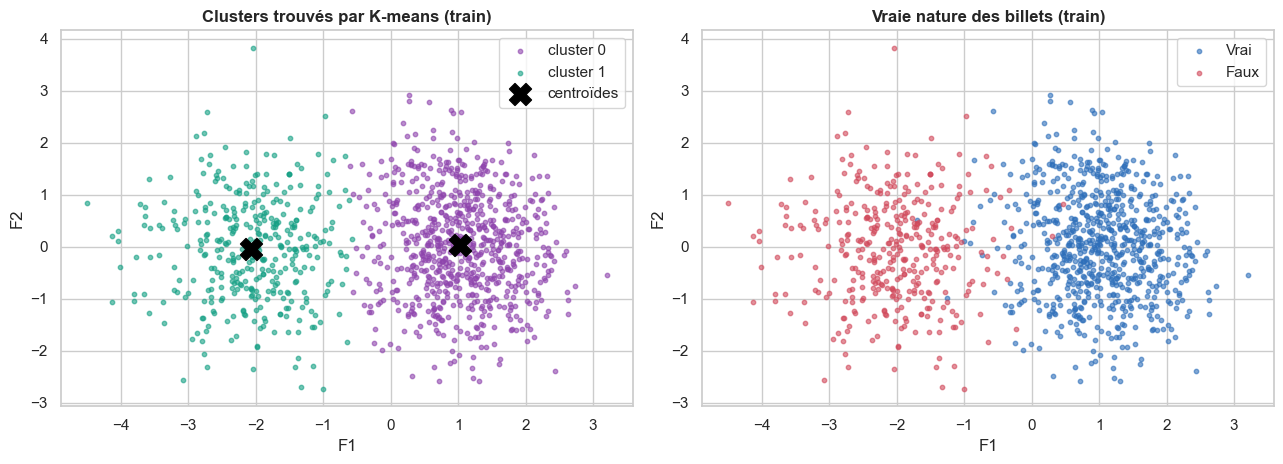

In [40]:
# 2) K-means à 2 clusters sur le TRAIN
kmeans = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(X_train_scaled)
clusters_train = kmeans.labels_
print(f"Silhouette moyenne (k=2) : {silhouette_score(X_train_scaled, clusters_train):.3f}")

# 3a) Forme des clusters : projection sur les 2 premiers axes de l'ACP (ajustée sur le train)
acp_train = PCA(n_components=2).fit(X_train_scaled)
proj = acp_train.transform(X_train_scaled)
proj_centres = acp_train.transform(kmeans.cluster_centers_)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for c, coul in zip([0, 1], ["#8e44ad", "#16a085"]):
    axes[0].scatter(proj[clusters_train == c, 0], proj[clusters_train == c, 1], s=10, alpha=0.6, c=coul, label=f"cluster {c}")
axes[0].scatter(proj_centres[:, 0], proj_centres[:, 1], marker="X", s=250, c="black", label="centroïdes")
axes[0].set(title="Clusters trouvés par K-means (train)", xlabel="F1", ylabel="F2"); axes[0].legend()
for t, val in [("Vrai", 0), ("Faux", 1)]:
    m = (y_train == val).values
    axes[1].scatter(proj[m, 0], proj[m, 1], s=10, alpha=0.6, c=COULEURS[t], label=t)
axes[1].set(title="Vraie nature des billets (train)", xlabel="F1", ylabel="F2"); axes[1].legend()
plt.tight_layout(); plt.show()

In [41]:
# 3b) Caractérisation des clusters : mesures moyennes (en mm, données imputées non standardisées)
profil = pd.DataFrame(X_train_imp, columns=VARIABLES).assign(cluster=clusters_train).groupby("cluster").mean()
profil["nb billets"] = pd.Series(clusters_train).value_counts().sort_index()
display(profil.round(3))

# Centroïdes ramenés en millimètres (transformation inverse de la standardisation)
display(pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=VARIABLES,
                     index=["centroïde cluster 0", "centroïde cluster 1"]).round(3))

# 4) Composition des clusters selon la vraie étiquette (on ne l'utilise QU'APRÈS le clustering)
composition = pd.crosstab(pd.Series(clusters_train, name="cluster"),
                          y_train.reset_index(drop=True).map({0: "Vrai", 1: "Faux"}).rename("réalité"))
display(composition)

,diagonal,height_left,height_right,margin_low,margin_up,length,nb billets
cluster,,,,,,,
0,171.99,103.945,103.807,4.115,3.051,113.192,751
1,171.89,104.203,104.159,5.214,3.352,111.631,374


,diagonal,height_left,height_right,margin_low,margin_up,length
centroïde cluster 0,171.99,103.945,103.807,4.115,3.051,113.192
centroïde cluster 1,171.89,104.203,104.159,5.214,3.352,111.631


réalité,Faux,Vrai
cluster,,
0,10,741
1,365,9


Correspondance cluster -> étiquette : {0: 'Vrai', 1: 'Faux'}


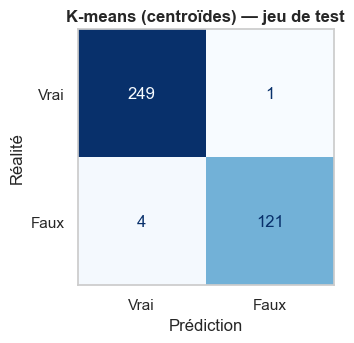

              precision    recall  f1-score   support

    Vrai (0)      0.984     0.996     0.990       250
    Faux (1)      0.992     0.968     0.980       125

    accuracy                          0.987       375
   macro avg      0.988     0.982     0.985       375
weighted avg      0.987     0.987     0.987       375

→ 4 faux billet(s) non détecté(s) (FN) | 1 vrai(s) billet(s) accusé(s) à tort (FP)


In [42]:
# Association cluster -> étiquette : chaque cluster prend la classe majoritaire de ses billets du train
correspondance = {c: int(y_train.reset_index(drop=True)[clusters_train == c].mean() > 0.5) for c in [0, 1]}
print("Correspondance cluster -> étiquette :", {c: ("Faux" if v else "Vrai") for c, v in correspondance.items()})

# Prédiction du TEST : centroïde le plus proche (kmeans.predict) puis traduction en vrai/faux
clusters_test = kmeans.predict(X_test_scaled)
pred_km = np.array([correspondance[c] for c in clusters_test])

# Pseudo-probabilité d'être faux à partir des distances aux 2 centroïdes (pour tracer une courbe ROC)
dist = kmeans.transform(X_test_scaled)                       # distance de chaque billet à chaque centroïde
c_faux = [c for c, v in correspondance.items() if v == 1][0]
c_vrai = 1 - c_faux
proba_km = dist[:, c_vrai] / (dist[:, c_vrai] + dist[:, c_faux])   # proche du centroïde « faux » -> proche de 1

evaluer("K-means (centroïdes)", y_test, pred_km, proba_km)

#### Forme des clusters : diagramme de silhouette
Le coefficient de silhouette de chaque billet mesure s'il est plus proche de son propre cluster (proche de 1) que de l'autre (négatif = probablement mal classé).

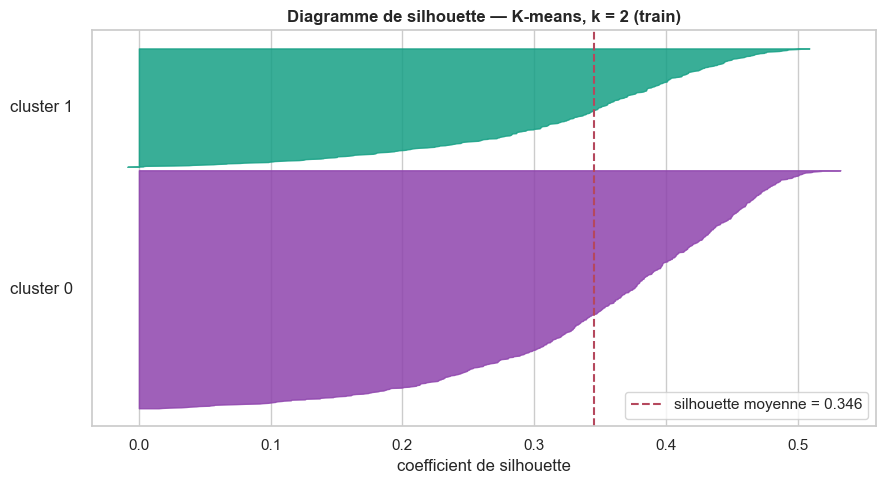

Billets au coefficient négatif (probablement mal placés) : 1 sur 1125


In [43]:
sil_vals = silhouette_samples(X_train_scaled, clusters_train)
fig, ax = plt.subplots(figsize=(9, 5))
y_bas = 10
for c, coul in zip([0, 1], ["#8e44ad", "#16a085"]):
    vals = np.sort(sil_vals[clusters_train == c])
    ax.fill_betweenx(np.arange(y_bas, y_bas + len(vals)), 0, vals, color=coul, alpha=.85)
    ax.text(-0.05, y_bas + len(vals) / 2, f"cluster {c}", ha="right", va="center")
    y_bas += len(vals) + 10
ax.axvline(sil_vals.mean(), color="#b5485d", ls="--", label=f"silhouette moyenne = {sil_vals.mean():.3f}")
ax.set(xlabel="coefficient de silhouette", yticks=[], title="Diagramme de silhouette — K-means, k = 2 (train)")
ax.legend(); plt.tight_layout(); plt.show()
print(f"Billets au coefficient négatif (probablement mal placés) : {(sil_vals < 0).sum()} sur {len(sil_vals)}")

#### Caractérisation : signature de chaque cluster
Écart de la moyenne de chaque cluster à la moyenne générale, en **écarts-types** (rouge = au-dessus, bleu = en dessous).

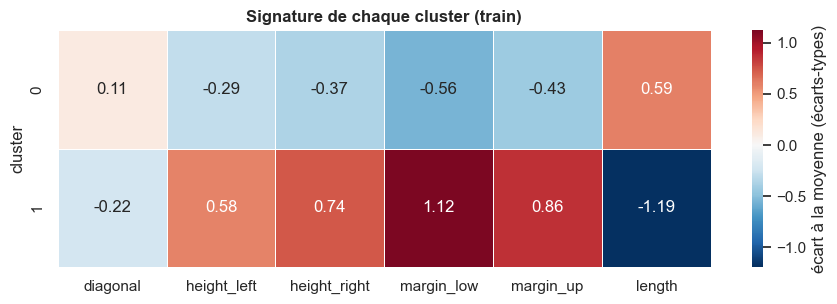

In [44]:
X_train_imp_df = pd.DataFrame(X_train_imp, columns=VARIABLES)
ecarts = (X_train_imp_df.groupby(clusters_train).mean() - X_train_imp_df.mean()) / X_train_imp_df.std()
plt.figure(figsize=(9, 3.2))
sns.heatmap(ecarts, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=.5,
            cbar_kws={"label": "écart à la moyenne (écarts-types)"})
plt.title("Signature de chaque cluster (train)"); plt.ylabel("cluster")
plt.tight_layout(); plt.show()

**Bilan K-means** :
- Sans jamais voir les étiquettes, l'algorithme a retrouvé **deux groupes qui correspondent presque parfaitement** aux vrais et aux faux billets (voir le tableau de composition).
- **Caractérisation** : le cluster « faux » regroupe les billets **plus courts**, aux **marges plus grandes** et aux **hauteurs légèrement supérieures** ; le cluster « vrai » l'inverse, exactement le profil observé en EDA.
- **Limites** : K-means n'est **pas conçu pour la classification**. Il suppose des clusters sphériques de taille comparable et n'optimise pas la détection des faux billets ; il ne fournit pas de vraie probabilité (notre pseudo-probabilité n'est qu'un ratio de distances). Il sert ici surtout à **confirmer que la structure vrai/faux existe naturellement dans les mesures**.

---
## 14. Sélection du meilleur modèle

### 14.1 Comparaison sur le jeu de test (375 billets jamais vus, dont 125 faux)

,Accuracy,Rappel (faux détectés),Précision,F1,AUC ROC,FN (faux non détectés),FP (vrais accusés à tort)
Régression logistique,0.989,0.968,1.000,0.984,0.996,4,0
KNN,0.989,0.968,1.000,0.984,0.984,4,0
Random Forest,0.984,0.960,0.992,0.976,0.998,5,1
K-means (centroïdes),0.987,0.968,0.992,0.980,0.993,4,1


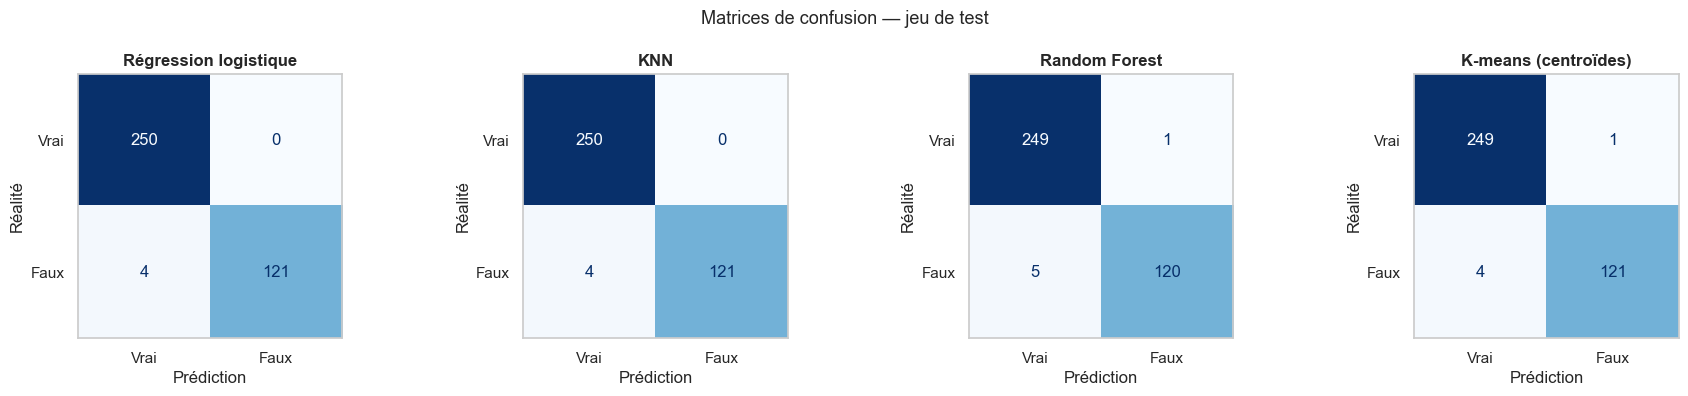

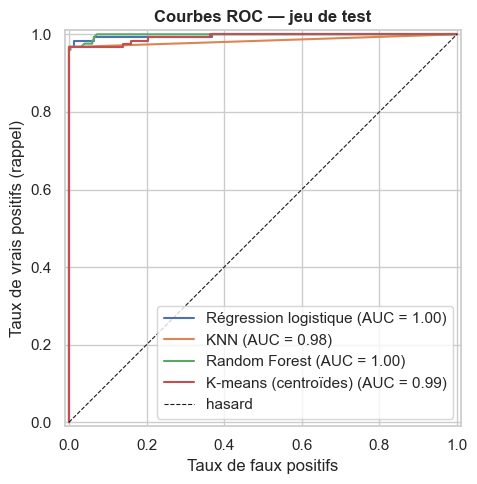

In [45]:
comparatif = pd.DataFrame(resultats_test).T
comparatif[["FN (faux non détectés)", "FP (vrais accusés à tort)"]] = comparatif[["FN (faux non détectés)", "FP (vrais accusés à tort)"]].astype(int)
display(comparatif.style.format({c: "{:.3f}" for c in ["Accuracy", "Rappel (faux détectés)", "Précision", "F1", "AUC ROC"]})
        .highlight_max(subset=["Accuracy", "Rappel (faux détectés)", "Précision", "F1", "AUC ROC"], color="#c6efce")
        .highlight_min(subset=["FN (faux non détectés)", "FP (vrais accusés à tort)"], color="#c6efce"))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (nom, pred) in zip(axes, predictions_test.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Vrai", "Faux"], cmap="Blues", colorbar=False, ax=ax)
    ax.set(title=nom, xlabel="Prédiction", ylabel="Réalité"); ax.grid(False)
plt.suptitle("Matrices de confusion — jeu de test", fontsize=13)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for nom, proba in probas_test.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=nom, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="hasard")
ax.set(title="Courbes ROC — jeu de test", xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs (rappel)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

### 14.2 Les écarts sont-ils significatifs ? Validation croisée répétée
Sur le test, les modèles ne diffèrent que de **quelques billets** : une différence de 1 billet = 0,8 point de rappel. Pour départager de façon robuste, on évalue chaque modèle (avec ses meilleurs hyperparamètres) en **validation croisée répétée sur le train** : 5 plis × 10 répétitions = **50 évaluations** par modèle.

In [46]:
modeles_finaux = {"Régression logistique": modele_lr, "KNN": modele_knn, "Random Forest": modele_rf}
lignes = []
for nom, pipe in modeles_finaux.items():
    r = cross_validate(pipe, X_train, y_train, cv=RCV, scoring=["recall", "precision", "f1", "roc_auc"])
    lignes.append({"modèle": nom,
                   "Rappel moyen": r["test_recall"].mean(), "Rappel écart-type": r["test_recall"].std(),
                   "Précision moyenne": r["test_precision"].mean(), "F1 moyen": r["test_f1"].mean(),
                   "AUC moyenne": r["test_roc_auc"].mean()})
cv_comparatif = pd.DataFrame(lignes).set_index("modèle")
display(cv_comparatif.round(4))

,Rappel moyen,Rappel écart-type,Précision moyenne,F1 moyen,AUC moyenne
modèle,,,,,
Régression logistique,0.982,0.014,0.991,0.986,1.000
KNN,0.980,0.015,0.989,0.984,0.994
Random Forest,0.985,0.013,0.991,0.988,0.999


### 14.3 Choix du modèle final : **la régression logistique**

| Critère | Constat |
|---|---|
| **Performance** | Au niveau des meilleurs sur le test (rappel, précision, F1). En validation croisée répétée, les 3 modèles supervisés sont **dans la marge d'incertitude** les uns des autres (écarts de rappel inférieurs à l'écart-type) : aucun n'est significativement supérieur. |
| **Probabilités fiables** | Elle produit une **vraie probabilité** (sigmoïde), bien étalée et exploitable pour fixer un seuil et une zone de contrôle manuel. Le KNN ne donne qu'une proportion de voisins (valeurs en escalier). |
| **Explicabilité** | Ses coefficients disent **pourquoi** un billet est jugé faux (longueur, marges), un argument important pour une organisation publique comme l'ONCFM, qui doit pouvoir justifier une saisie. |
| **Simplicité / robustesse** | Modèle léger, rapide, peu sensible au sur-apprentissage, et cohérent avec la structure **quasi linéairement séparable** des données mise en évidence en EDA. |

À performance équivalente, on privilégie le modèle **le plus simple et le plus explicable** (principe de parcimonie).

**Pourquoi pas les autres ?** Le **Random Forest** est aussi performant mais plus lourd et moins explicable, sans gain significatif. Le **KNN** ne fournit pas de probabilité fine et doit garder toutes les données en mémoire. Le **K-means** n'est pas un classifieur : il confirme la structure des données mais n'optimise pas la détection.

### 14.4 Utiliser les probabilités pour confirmer les résultats
La régression logistique donne pour chaque billet la **probabilité d'être faux**. Regardons comment elles se répartissent sur le test, et l'effet du **seuil de décision** (0,5 par défaut).

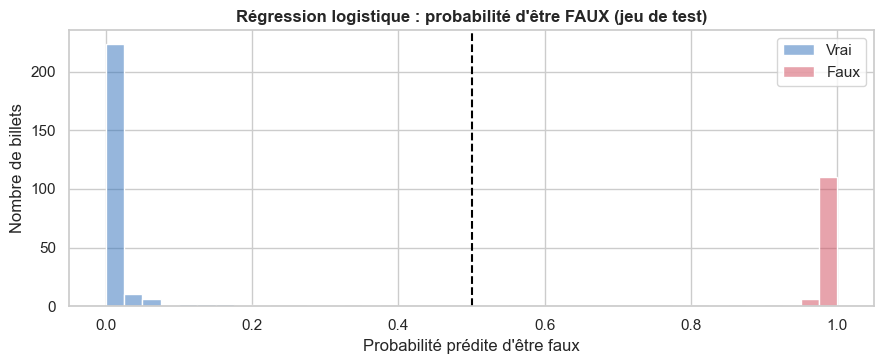

Part des billets du test dont la probabilité est très tranchée (< 0,05 ou > 0,95) : 93.9%


,Rappel,Précision,FN (faux ratés),FP (vrais accusés)
seuil,,,,
0.2,0.976,0.976,3,3
0.3,0.968,0.984,4,2
0.4,0.968,1.000,4,0
0.5,0.968,1.000,4,0
0.6,0.960,1.000,5,0


Billets mal classés au seuil 0,5 :


,diagonal,height_left,height_right,margin_low,margin_up,length,realite,proba_faux
1083,171.85,103.60,103.82,4.60,3.21,112.50,Faux,0.211
1122,172.09,104.15,104.17,4.15,3.40,113.85,Faux,0.003
1407,172.02,103.99,104.28,4.22,2.98,112.42,Faux,0.049
1103,171.88,104.05,103.75,4.41,3.21,112.52,Faux,0.192


In [47]:
proba_lr = probas_test["Régression logistique"]

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.histplot(x=proba_lr, hue=y_test.map({0: "Vrai", 1: "Faux"}).values, hue_order=["Vrai", "Faux"],
             palette=COULEURS, bins=40, ax=ax)
ax.axvline(0.5, color="black", ls="--", label="seuil 0,5")
ax.set(title="Régression logistique : probabilité d'être FAUX (jeu de test)", xlabel="Probabilité prédite d'être faux", ylabel="Nombre de billets")
plt.tight_layout(); plt.show()

print("Part des billets du test dont la probabilité est très tranchée (< 0,05 ou > 0,95) :",
      f"{((proba_lr < 0.05) | (proba_lr > 0.95)).mean():.1%}")

lignes = []
for seuil in [0.2, 0.3, 0.4, 0.5, 0.6]:
    p = (proba_lr >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    lignes.append({"seuil": seuil, "Rappel": recall_score(y_test, p), "Précision": precision_score(y_test, p),
                   "FN (faux ratés)": fn, "FP (vrais accusés)": fp})
display(pd.DataFrame(lignes).set_index("seuil").round(3))

# Les billets mal classés au seuil 0,5 : quelle était leur probabilité ?
erreurs = X_test.assign(realite=y_test.map({0: "Vrai", 1: "Faux"}), proba_faux=proba_lr)[
    (proba_lr >= 0.5).astype(int) != y_test.values]
print("Billets mal classés au seuil 0,5 :")
display(erreurs.round(3))

**Lecture** :
- **94 %** des billets du test reçoivent une probabilité **très tranchée** (< 0,05 ou > 0,95) : le modèle est sûr de lui dans la grande majorité des cas.
- Les **4 faux billets ratés** se répartissent en deux cas :
  - **2 billets à la frontière** (probabilités ≈ 0,19 et ≈ 0,21) : le modèle « hésitait » ;
  - **2 billets aux mesures typiques d'un vrai billet** (probabilités ≈ 0,003 et ≈ 0,05) : avec ces 6 mesures, ils ressemblent en tout point à des vrais — ce sont d'excellentes contrefaçons. Aucun des 4 algorithmes ne descend d'ailleurs sous 4 faux billets ratés sur le test.
- **Effet du seuil** : descendre à 0,2 rattrape **1 seul** faux de plus, au prix de **3 vrais billets** accusés à tort. Le gain est faible et non garanti : on conserve le **seuil de 0,5**.

**Mieux qu'un seuil : une zone de contrôle manuel.** Plutôt que de basculer la décision, on signale les billets dont la probabilité est intermédiaire. Pour fixer cette zone **sans utiliser le test** (sinon on l'ajusterait sur les données d'évaluation), on utilise les probabilités **hors échantillon** du train : chaque billet est prédit par un modèle qui ne l'a pas vu (validation croisée).

In [48]:
proba_oof = cross_val_predict(creer_pipeline(LogisticRegression(max_iter=1000, C=gs_lr.best_params_["logisticregression__C"])),
                              X_train, y_train, cv=CV, method="predict_proba")[:, 1]
erreurs_oof = (proba_oof >= 0.5).astype(int) != y_train.values
print(f"Erreurs hors échantillon sur le train (seuil 0,5) : {erreurs_oof.sum()} sur {len(y_train)}")

lignes = []
for bas, haut in [(0.2, 0.8), (0.1, 0.9), (0.05, 0.95)]:
    zone = (proba_oof > bas) & (proba_oof < haut)
    lignes.append({"zone de contrôle": f"{bas} – {haut}", "billets à contrôler": int(zone.sum()),
                   "% des billets": round(zone.mean() * 100, 1),
                   "erreurs captées par la zone": f"{int((erreurs_oof & zone).sum())} / {int(erreurs_oof.sum())}"})
display(pd.DataFrame(lignes).set_index("zone de contrôle"))

ZONE_INCERTITUDE = (0.1, 0.9)
zone_test = (proba_lr > ZONE_INCERTITUDE[0]) & (proba_lr < ZONE_INCERTITUDE[1])
erreurs_test = (proba_lr >= 0.5).astype(int) != y_test.values
print(f"Vérification sur le test avec la zone {ZONE_INCERTITUDE} : {zone_test.sum()} billets signalés "
      f"({zone_test.mean():.1%}), dont {int((erreurs_test & zone_test).sum())} des {int(erreurs_test.sum())} erreurs.")

Erreurs hors échantillon sur le train (seuil 0,5) : 10 sur 1125


,billets à contrôler,% des billets,erreurs captées par la zone
zone de contrôle,,,
0.2 – 0.8,25,2.2,6 / 10
0.1 – 0.9,51,4.5,9 / 10
0.05 – 0.95,83,7.4,10 / 10


Vérification sur le test avec la zone (0.1, 0.9) : 15 billets signalés (4.0%), dont 2 des 4 erreurs.


**Décision pour l'application** :
- **Prédiction binaire au seuil de 0,5** (VRAI / FAUX).
- **Affichage de la probabilité** d'être faux pour chaque billet : elle **confirme** la prédiction (0,999 est une quasi-certitude, 0,45 ne l'est pas).
- **Zone de contrôle manuel entre 0,1 et 0,9** : sur le train, elle ne concerne qu'environ **4,5 % des billets** mais capte la **grande majorité des erreurs** (voir tableau). Sur le test, elle signale les 2 faux billets « frontière » ; les 2 contrefaçons parfaites restent indétectables avec ces seules mesures.

---
## 15. Sauvegarde du modèle final et test sur `billets_production.csv`

### 15.1 Ré-entraînement sur les 1 500 billets puis sauvegarde
L'évaluation est terminée et le modèle choisi. Pour la production, on **ré-entraîne le même pipeline** (mêmes hyperparamètres) sur **l'ensemble des 1 500 billets** : plus de données = modèle plus robuste. C'est la pratique standard ; la performance attendue est celle mesurée sur le test.

Sauvegarder un modèle implique de sauvegarder **aussi les étapes de prétraitement** : notre pipeline contient l'**imputation** (régression linéaire), le **StandardScaler** et la **régression logistique**. Un seul fichier suffit donc à faire des prédictions sur des mesures brutes.

In [49]:
pipeline_final = make_pipeline(
    IterativeImputer(estimator=LinearRegression(), random_state=RANDOM_STATE),
    StandardScaler(),
    LogisticRegression(max_iter=1000, C=gs_lr.best_params_["logisticregression__C"]))
pipeline_final.fit(X, y)
print(pipeline_final)

FICHIER_MODELE = "modele_faux_billets.joblib"
joblib.dump({"pipeline": pipeline_final, "variables": VARIABLES, "classe_positive": "faux (1)",
             "seuil": 0.5, "zone_incertitude": ZONE_INCERTITUDE, "sklearn_version": sklearn.__version__},
            FICHIER_MODELE)
print(f" Modèle sauvegardé dans '{FICHIER_MODELE}' (scikit-learn {sklearn.__version__})")

Pipeline(steps=[('iterativeimputer',
                 IterativeImputer(estimator=LinearRegression(),
                                  random_state=42)),
                ('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(C=1, max_iter=1000))])
 Modèle sauvegardé dans 'modele_faux_billets.joblib' (scikit-learn 1.7.2)


### 15.2 Rechargement et test sur le fichier de production
On recharge le fichier sauvegardé (comme le fera l'application) et on prédit les billets de `billets_production.csv`.
Ce fichier utilise la **virgule** comme séparateur et ses colonnes ne sont **pas dans le même ordre** : on sélectionne donc les colonnes **par leur nom**.

In [50]:
sauvegarde = joblib.load(FICHIER_MODELE)
modele = sauvegarde["pipeline"]

prod = pd.read_csv("billets_production.csv")
display(prod)

proba_prod = modele.predict_proba(prod[sauvegarde["variables"]])[:, 1]
resultat = pd.DataFrame({"id": prod["id"],
                         "prediction": np.where(proba_prod >= sauvegarde["seuil"], "FAUX", "VRAI"),
                         "proba_faux": proba_prod})
display(resultat.style.format({"proba_faux": "{:.4f}"}))

,diagonal,height_left,height_right,margin_low,margin_up,length,id
0,171.76,104.01,103.54,5.21,3.30,111.42,A_1
1,171.87,104.17,104.13,6.00,3.31,112.09,A_2
2,172.00,104.58,104.29,4.99,3.39,111.57,A_3
3,172.49,104.55,104.34,4.44,3.03,113.20,A_4
4,171.65,103.63,103.56,3.77,3.16,113.33,A_5


,id,prediction,proba_faux
0,A_1,FAUX,0.9989
1,A_2,FAUX,0.9999
2,A_3,FAUX,0.9997
3,A_4,VRAI,0.0206
4,A_5,VRAI,0.0001


### 15.3 L'application
L'application de production est livrée dans un **script séparé** : `Rizki_Sabah_2_Script_application_102026.py`. Elle accepte, comme le demande le cahier des charges :
- soit un **chemin vers un fichier CSV** contenant plusieurs billets,
- soit les **6 valeurs géométriques** d'un seul billet,

et renvoie une **sortie binaire** (VRAI / FAUX) accompagnée de la probabilité.
Test depuis ce notebook :

In [51]:
import glob
# Le script de l'application est dans le même dossier ; on le retrouve par son nom de livrable
SCRIPT = sorted(glob.glob("*_2_Script_application_*.py"))[0]
print("Script utilisé :", SCRIPT)
%run $SCRIPT --csv billets_production.csv

Script utilisé : Rizki_Sabah_2_Script_application_102026.py

=== Résultats de la détection ===
 id  prediction resultat proba_faux controle
A_1           1     FAUX     0.9989         
A_2           1     FAUX     0.9999         
A_3           1     FAUX     0.9997         
A_4           0     VRAI     0.0206         
A_5           0     VRAI     0.0001         

Bilan : 5 billet(s) analysé(s) -> 3 FAUX, 2 VRAI(S).


In [52]:
# Un seul billet, valeurs dans l'ordre : diagonal height_left height_right margin_low margin_up length
%run $SCRIPT --valeurs 171.76 104.01 103.54 5.21 3.30 111.42


=== Résultats de la détection ===
          id  prediction resultat proba_faux controle
billet_saisi           1     FAUX     0.9989         

Bilan : 1 billet(s) analysé(s) -> 1 FAUX, 0 VRAI(S).


---
## 16. Synthèse

### Ce qui a été produit

- Un jeu de données **nettoyé** (`billets_nettoyes.csv`, 1 500 billets, zéro valeur manquante) et son **dictionnaire des variables**.
- Un **modèle sauvegardé** (`modele_faux_billets.joblib`) : imputation + standardisation + régression logistique.
- Une **application** : le script `Rizki_Sabah_2_Script_application_102026.py` (CSV ou valeurs d'un billet, sortie binaire, probabilité, zone de contrôle manuel entre 0,1 et 0,9).

### Démarche suivie

| Étape | Décision et justification |
|---|---|
| **Structure** | fichier déjà au format « un billet = une ligne » : ni pivot ni fusion nécessaires |
| **Contrôle qualité** | 0 doublon, mesures toutes plausibles, 1 000 vrais / 500 faux conformes au cahier des charges |
| **Valeurs manquantes** | 37 `margin_low` imputées par **régression linéaire** sur les 5 autres mesures (erreur −28 % vs la moyenne), sans utiliser la cible |
| **Valeurs extrêmes** | **conservées** : mesures plausibles, souvent des faux billets ; asymétries faibles → pas de transformation log |
| **Variables** | `length`, `margin_low`, `margin_up` les plus discriminantes ; les 6 mesures conservées (aucune redondance, sous-ensembles testés sans gain) |
| **ACP** | F1 (≈ 43 %) = axe vrai ↔ faux ; deux groupes quasi linéairement séparables |
| **Découpage** | train 75 % / test 25 %, **stratifié**, `random_state = 42` ; réglages par validation croisée sur le train |
| **Fuite de données** | imputation et standardisation **dans le pipeline**, apprises sur le train seul |
| **Modèles** | 3 supervisés ≈ 99 % d'exactitude sur le test ; K-means retrouve sans étiquette les 2 familles |
| **Modèle retenu** | **régression logistique** : au meilleur niveau, explicable, vraies probabilités, simple |
| **Probabilités** | seuil 0,5 conservé ; zone de contrôle 0,1 – 0,9 calibrée sur le train (9 erreurs sur 10 captées) |

### Pistes d'amélioration

Collecter davantage de faux billets récents (les faussaires évoluent), surveiller la performance dans le temps, ajuster le seuil avec l'ONCFM selon le coût réel d'un faux non détecté, tester d'autres algorithmes (SVM, gradient boosting, analyse discriminante linéaire).